<a href="https://colab.research.google.com/github/tipismaca/Trabajo-Bebidas-del-Maipo-SA/blob/main/Codigo/CasodeEstudio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Caso de Estudio: Bebidas del Maipo S.A.
**Objetivo:** Implementar control estadístico de procesos (Fase I y II) y pronóstico de demanda sin fuga temporal.

## 1. Configuración Inicial
Importación de librerías, configuración de gráficos y fijación de semillas globales para garantizar la reproducibilidad exacta de los resultados.

In [19]:
# ENTREGA 1 — CALIDAD Y PRONOSTICO
!rm -rf Trabajo-Bebidas-del-Maipo-SA #lo que hace esta linea es que elimina la clonacion anterior (la con coma)
!git clone https://github.com/tipismaca/Trabajo-Bebidas-del-Maipo-SA.git

Cloning into 'Trabajo-Bebidas-del-Maipo-SA'...
remote: Enumerating objects: 413, done.
remote: Counting objects: 100% (59/59), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 413 (delta 34), reused 17 (delta 14), pack-reused 354 (from 1)
Receiving objects: 100% (413/413), 38.93 MiB | 32.73 MiB/s, done.
Resolving deltas: 100% (227/227), done.


In [32]:
%pip install -q statsforecast hierarchicalforecast

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, HTML
import math
from html import escape
import numpy as np
import seaborn as sns
from IPython.display import display
from scipy.stats import norm
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, SeasonalNaive, AutoARIMA
from hierarchicalforecast.utils import aggregate
from hierarchicalforecast.core import HierarchicalReconciliation
from hierarchicalforecast.methods import BottomUp, TopDown, MiddleOut
import random
import os

# Fijar semillas globales para garantizar la reproducibilidad (feedback de corrección)
def set_semillas(seed=42):
    np.random.seed(seed)
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_semillas()

#Parte A. Control estadístico y capacidad de proceso
**Objetivo:** Implementar control estadístico de procesos Fase I y II



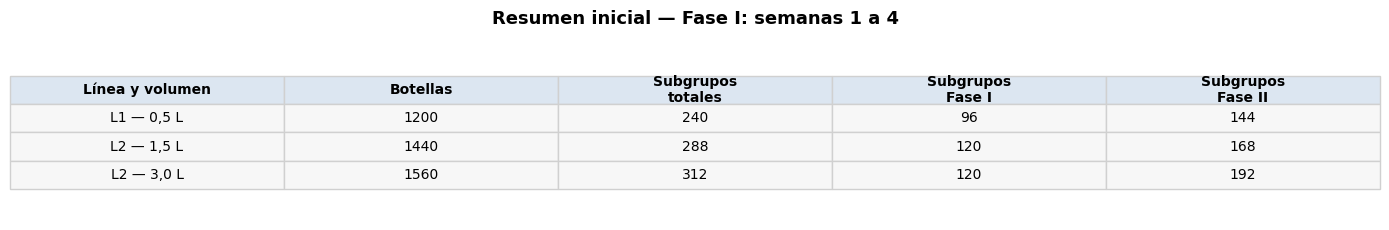

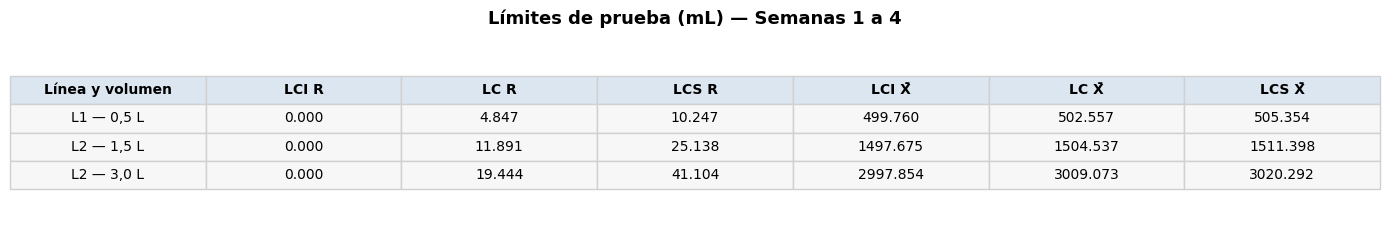

In [4]:
# ENTREGA 1 — PARTE A: CALIDAD

ruta_base = "Trabajo-Bebidas-del-Maipo-SA/Datos_crudos/"


# ==================================================
# 1. IMPORTAR LIBRERÍAS Y LEER LOS DATOS
# ==================================================


llenado = pd.read_csv(ruta_base + "calidad_llenado.csv")


# ==================================================
# 2. PREPARAR EL ORDEN TEMPORAL
# ==================================================

llenado["fecha_hora"] = pd.to_datetime(
    llenado["fecha"] + " " + llenado["hora"]
)

# Mantenemos la interpretación del turno C:
# las horas de madrugada corresponden al día siguiente
# de la fecha de inicio del turno.

madrugada = (
    llenado["turno"].str.startswith("C")
    & (llenado["fecha_hora"].dt.hour < 6)
)

llenado.loc[madrugada, "fecha_hora"] = (
    llenado.loc[madrugada, "fecha_hora"]
    + pd.Timedelta(days=1)
)


# ==================================================
# 3. CALCULAR EL PROMEDIO Y EL RANGO POR SUBGRUPO
# ==================================================
# Respetamos los subgrupos definidos en el archivo.

subgrupos = llenado.groupby(
    ["linea", "formato_L", "subgrupo"],
    as_index=False
).agg(
    fecha_hora=("fecha_hora", "first"),
    semana_registro=("semana_registro", "first"),
    turno=("turno", "first"),
    sku=("sku", "first"),
    botellas=("volumen_mL", "size"),
    promedio=("volumen_mL", "mean"),
    minimo=("volumen_mL", "min"),
    maximo=("volumen_mL", "max")
)

subgrupos["rango"] = subgrupos["maximo"] - subgrupos["minimo"]


# ==================================================
# 4. CONSTANTES TABULADAS PARA CINCO BOTELLAS
# ==================================================

A2 = 0.577
D3 = 0
D4 = 2.114

combinaciones = [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]

resultados = {}
resumen = []
tabla_limites = []


# ==================================================
# 5. DEFINIR LAS FASES Y CALCULAR LOS LÍMITES
# ==================================================

for linea, formato in combinaciones:

    # Seleccionar una línea y un formato.
    datos = subgrupos[
        (subgrupos["linea"] == linea)
        & (subgrupos["formato_L"] == formato)
    ].copy()

    # Ordenar los subgrupos cronológicamente.
    datos = datos.sort_values(
        ["fecha_hora", "subgrupo"]
    ).reset_index(drop=True)

    # Numeración para el eje X de cada combinación.
    datos["numero_subgrupo"] = range(1, len(datos) + 1)

    # Fase I: semanas 1, 2, 3 y 4.
    fase1 = datos[
        datos["semana_registro"].between(1, 4)
    ].copy()

    # Fase II: desde la semana 5.
    fase2 = datos[
        datos["semana_registro"] >= 5
    ].copy()

    # Promedio de los rangos de Fase I.
    R_barra = fase1["rango"].mean()

    # Promedio de las medias de Fase I.
    X_barra_barra = fase1["promedio"].mean()

    # Límites de la carta R.
    LCI_R = D3 * R_barra
    LC_R = R_barra
    LCS_R = D4 * R_barra

    # Límites de la carta X barra.
    LCI_X = X_barra_barra - A2 * R_barra
    LC_X = X_barra_barra
    LCS_X = X_barra_barra + A2 * R_barra

    # Guardar los resultados para graficarlos después.
    resultados[(linea, formato)] = {
        "datos": datos,
        "fase1": fase1,
        "fase2": fase2,
        "LCI_R": LCI_R,
        "LC_R": LC_R,
        "LCS_R": LCS_R,
        "LCI_X": LCI_X,
        "LC_X": LC_X,
        "LCS_X": LCS_X
    }

    volumen = str(formato).replace(".", ",")
    nombre = f"{linea} — {volumen} L"

    resumen.append([
        nombre,
        int(datos["botellas"].sum()),
        len(datos),
        len(fase1),
        len(fase2)
    ])

    tabla_limites.append([
        nombre,
        f"{LCI_R:.3f}",
        f"{LC_R:.3f}",
        f"{LCS_R:.3f}",
        f"{LCI_X:.3f}",
        f"{LC_X:.3f}",
        f"{LCS_X:.3f}"
    ])


# ==================================================
# 6. MOSTRAR LAS TABLAS RESUMEN
# ==================================================
# Esta función permite usar el mismo formato
# para las dos tablas.

def mostrar_tabla(titulo, columnas, filas):

    fig, ax = plt.subplots(figsize=(14, 2.4))

    ax.axis("off")
    ax.set_title(
        titulo,
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    tabla = ax.table(
        cellText=filas,
        colLabels=columnas,
        cellLoc="center",
        colLoc="center",
        loc="center"
    )

    tabla.auto_set_font_size(False)
    tabla.set_fontsize(10)
    tabla.scale(1, 1.8)

    for posicion, celda in tabla.get_celld().items():

        fila = posicion[0]
        celda.set_edgecolor("#D0D0D0")

        if fila == 0:
            celda.set_facecolor("#DCE6F1")
            celda.set_text_props(weight="bold")
        else:
            celda.set_facecolor("#F7F7F7")

    plt.tight_layout()
    plt.show()


mostrar_tabla(
    "Resumen inicial — Fase I: semanas 1 a 4",
    [
        "Línea y volumen",
        "Botellas",
        "Subgrupos\ntotales",
        "Subgrupos\nFase I",
        "Subgrupos\nFase II"
    ],
    resumen
)

mostrar_tabla(
    "Límites de prueba (mL) — Semanas 1 a 4",
    [
        "Línea y volumen",
        "LCI R",
        "LC R",
        "LCS R",
        "LCI X̄",
        "LC X̄",
        "LCS X̄"
    ],
    tabla_limites
)

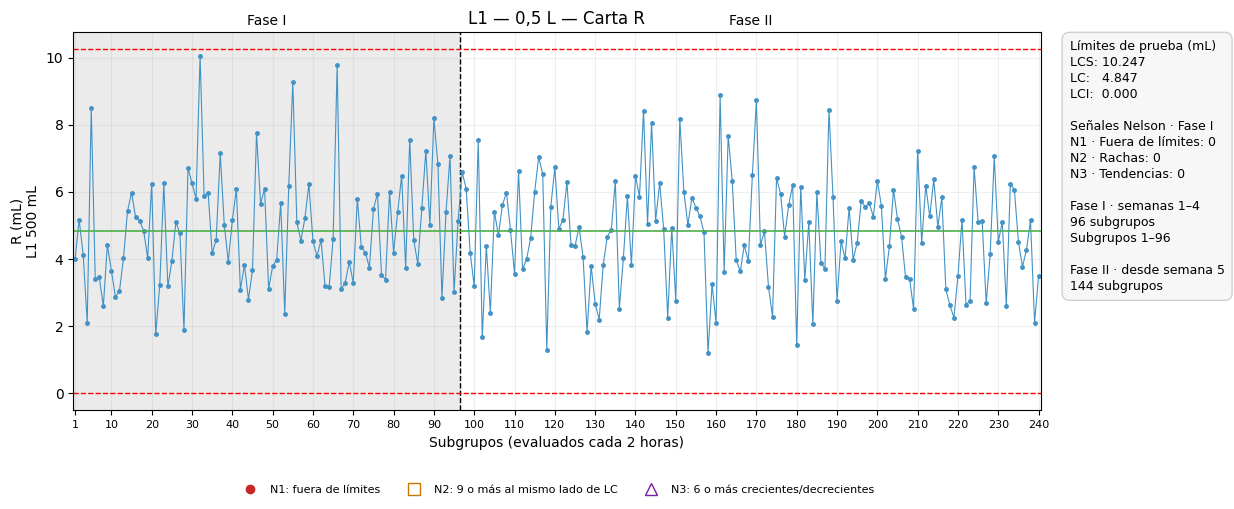

Fase I: sin señales de N1, N2 o N3.


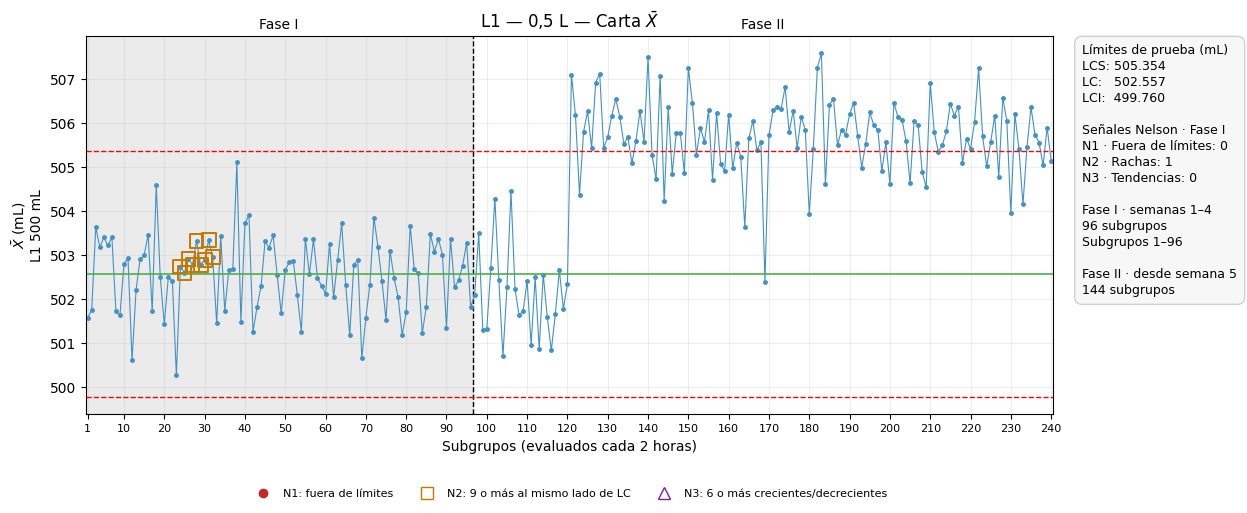

Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N2 · Racha,Sobre LC,24,B (14-22),1,NEC-D05,1
N2 · Racha,Sobre LC,"25, 26, 27, 28",A (06-14),2,NEC-D05,4
N2 · Racha,Sobre LC,"29, 30, 31, 32",B (14-22),2,CIT-L05,4


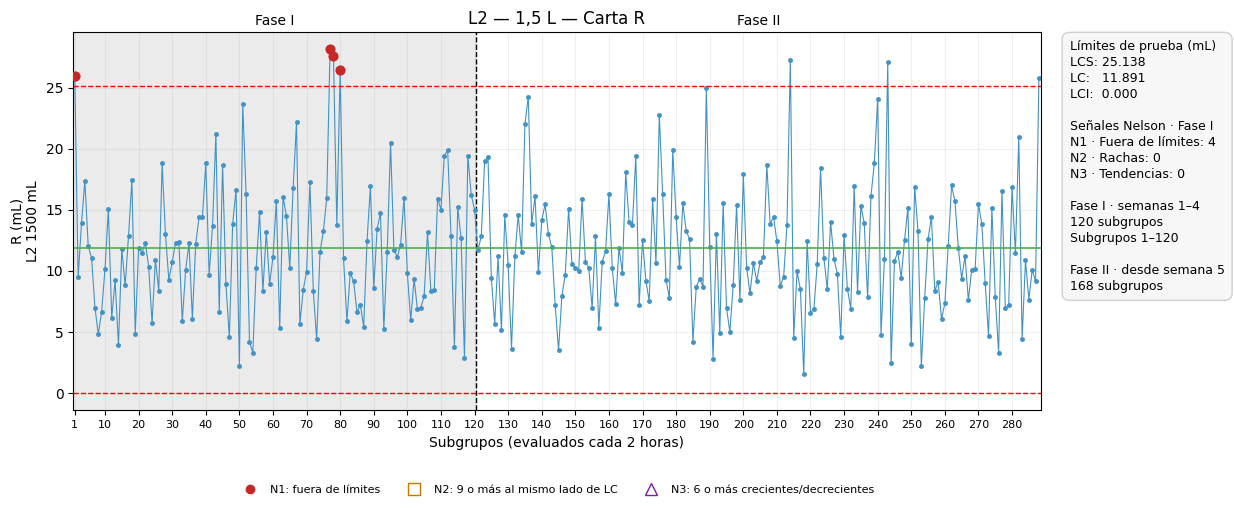

Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N1 · Fuera de límites,Sobre LCS,1,C (22-06),1,NEC-D15,1
N1 · Fuera de límites,Sobre LCS,77,C (22-06),3,FUN-B15,1
N1 · Fuera de límites,Sobre LCS,78,C (22-06),3,FUN-B15,1
N1 · Fuera de límites,Sobre LCS,80,C (22-06),3,FUN-B15,1


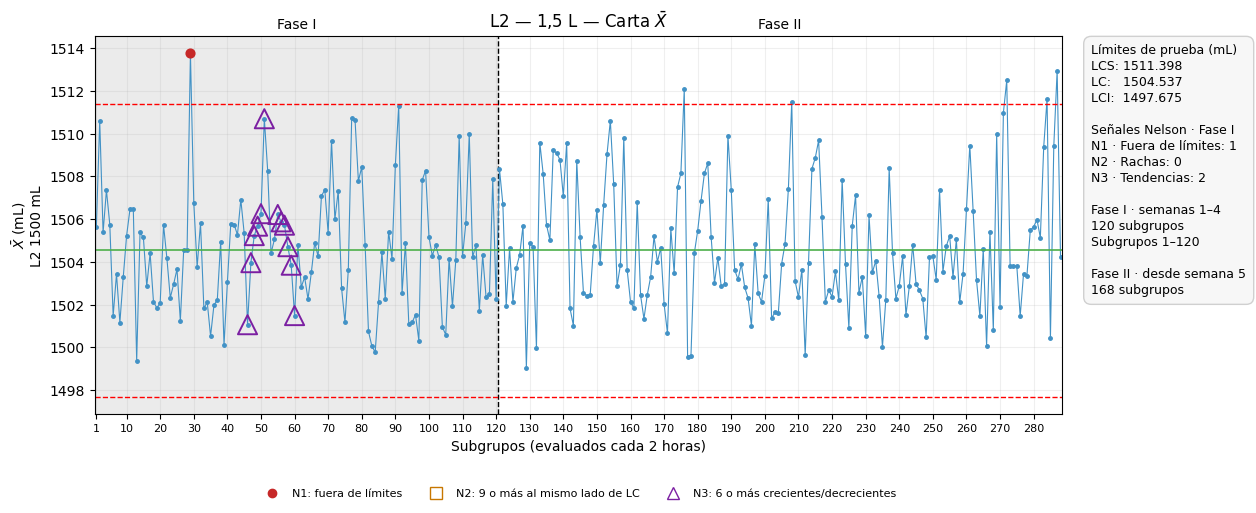

Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N1 · Fuera de límites,Sobre LCS,29,C (22-06),2,NEC-D15,1
N3 · Tendencia,Creciente,"46, 47, 48",A (06-14),2,FUN-B15,3
N3 · Tendencia,Creciente,"49, 50, 51",C (22-06),2,FUN-B15,3
N3 · Tendencia,Decreciente,"55, 56, 57, 58, 59, 60",A (06-14),3,CIT-L15,6


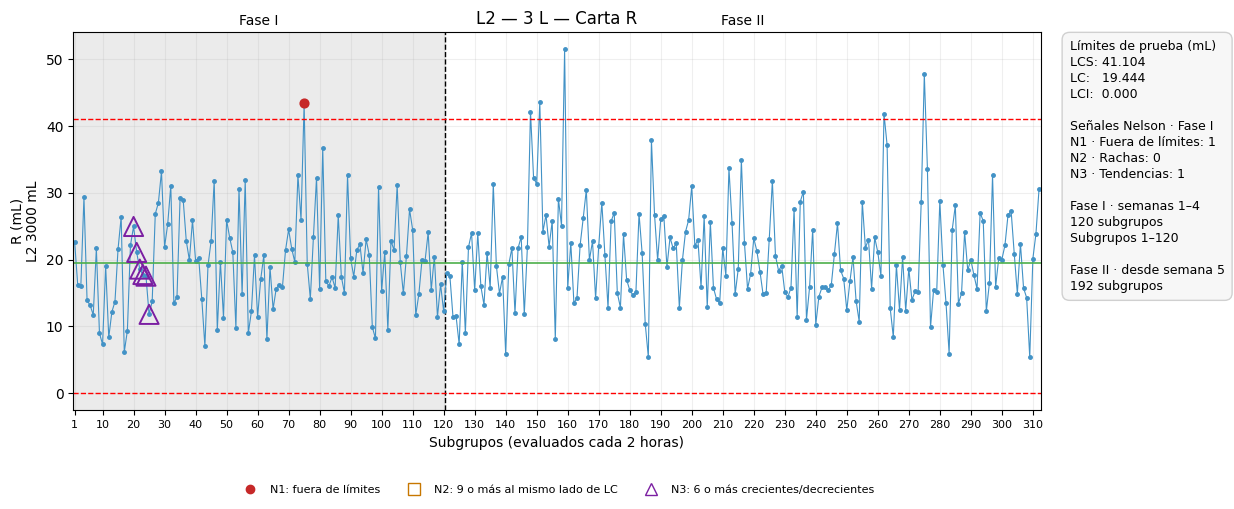

Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N3 · Tendencia,Decreciente,20,B (14-22),1,FUN-B30,1
N3 · Tendencia,Decreciente,"21, 22, 23, 24",C (22-06),1,FUN-B30,4
N3 · Tendencia,Decreciente,25,B (14-22),1,NEC-D30,1
N1 · Fuera de límites,Sobre LCS,75,C (22-06),3,FUN-B30,1


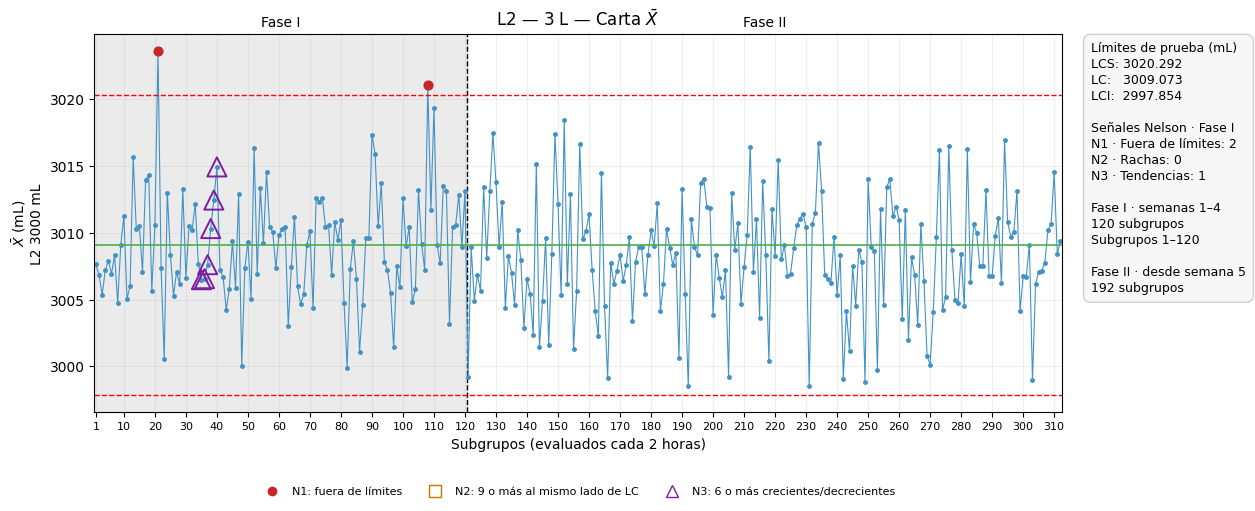

Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N1 · Fuera de límites,Sobre LCS,21,C (22-06),1,FUN-B30,1
N3 · Tendencia,Creciente,"35, 36",B (14-22),1,NEC-D30,2
N3 · Tendencia,Creciente,"37, 38, 39, 40",C (22-06),1,NEC-D30,4
N1 · Fuera de límites,Sobre LCS,108,C (22-06),4,FUN-B30,1


Línea y volumen,Fase I inicial,Subgrupos excluidos,Fase I conservada,Fase II
"L1 — 0,5 L",96,—,96,144
"L2 — 1,5 L",120,"1, 29, 77, 78, 80, 91",114,168
L2 — 3 L,120,"21, 75, 108",117,192


Línea y volumen,LCI R,LC R,LCS R,LCI X̄,LC X̄,LCS X̄
"L1 — 0,5 L",0.000,4.847,10.247,499.760,502.557,505.354
"L2 — 1,5 L",0.000,11.370,24.036,1497.684,1504.244,1510.805
L2 — 3 L,0.000,19.215,40.621,2997.747,3008.834,3019.921


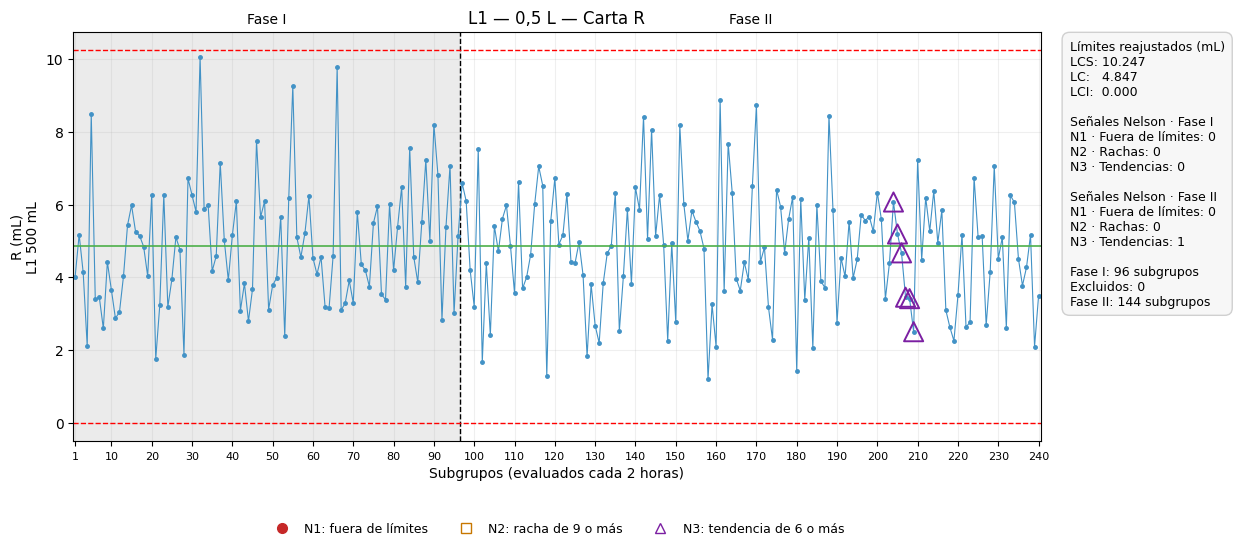

Fase I — Evidencia de las señales — L1 · 0,5 L — R: sin señales N1, N2 o N3.


Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N3 · Tendencia,Decreciente,204,A (06-14),9,CIT-L05,1
N3 · Tendencia,Decreciente,"205, 206, 207, 208",B (14-22),9,FUN-B05,4
N3 · Tendencia,Decreciente,209,A (06-14),9,FUN-B05,1


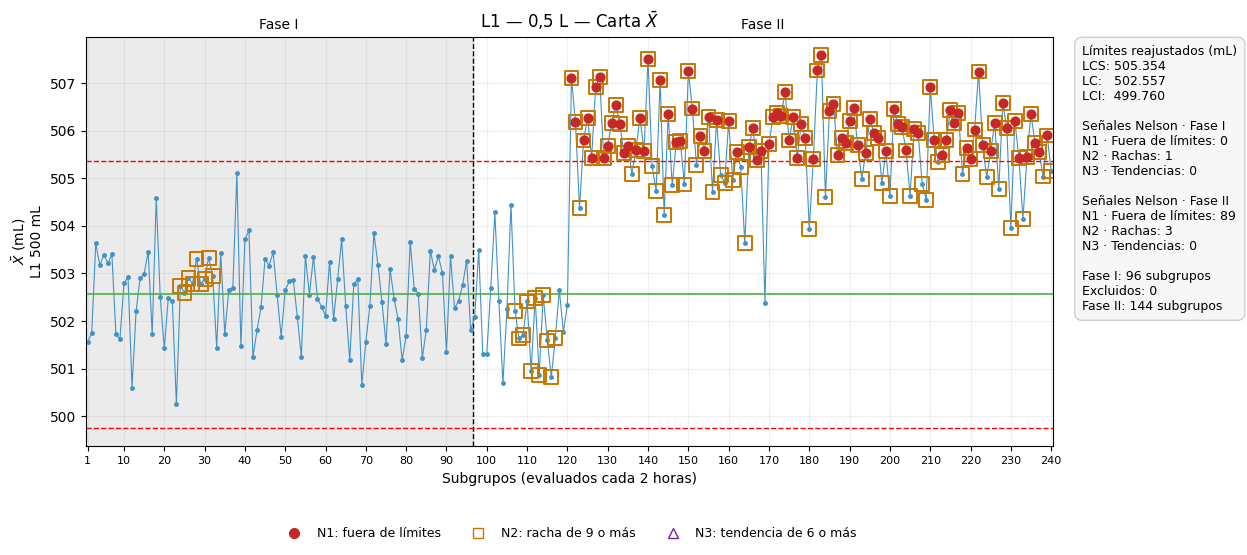

Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N2 · Racha,Sobre LC,24,B (14-22),1,NEC-D05,1
N2 · Racha,Sobre LC,"25, 26, 27, 28",A (06-14),2,NEC-D05,4
N2 · Racha,Sobre LC,"29, 30, 31, 32",B (14-22),2,CIT-L05,4


Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N2 · Racha,Bajo LC,"107, 108",A (06-14),5,FUN-B05,2
N2 · Racha,Bajo LC,"109, 110, 111, 112, 117",B (14-22),5,CIT-L05,5
N2 · Racha,Bajo LC,"113, 114, 115, 116",A (06-14),5,CIT-L05,4
N1 · Fuera de límites,Sobre LCS,121,A (06-14),6,CIT-L05,1
N2 · Racha,Sobre LC,"121, 122, 123, 124, 129, 130, 131, 132",A (06-14),6,CIT-L05,8
N2 · Racha,Sobre LC,"125, 126, 127, 128",B (14-22),6,NEC-D05,4
N2 · Racha,Sobre LC,"133, 134, 135, 136, 141, 142, 143, 144",B (14-22),6,FUN-B05,8
N2 · Racha,Sobre LC,"137, 138, 139, 140",A (06-14),6,NEC-D05,4
N2 · Racha,Sobre LC,"145, 146, 147, 148, 153, 154, 155, 156",A (06-14),7,FUN-B05,8
N2 · Racha,Sobre LC,"149, 150, 151, 152",B (14-22),7,CIT-L05,4


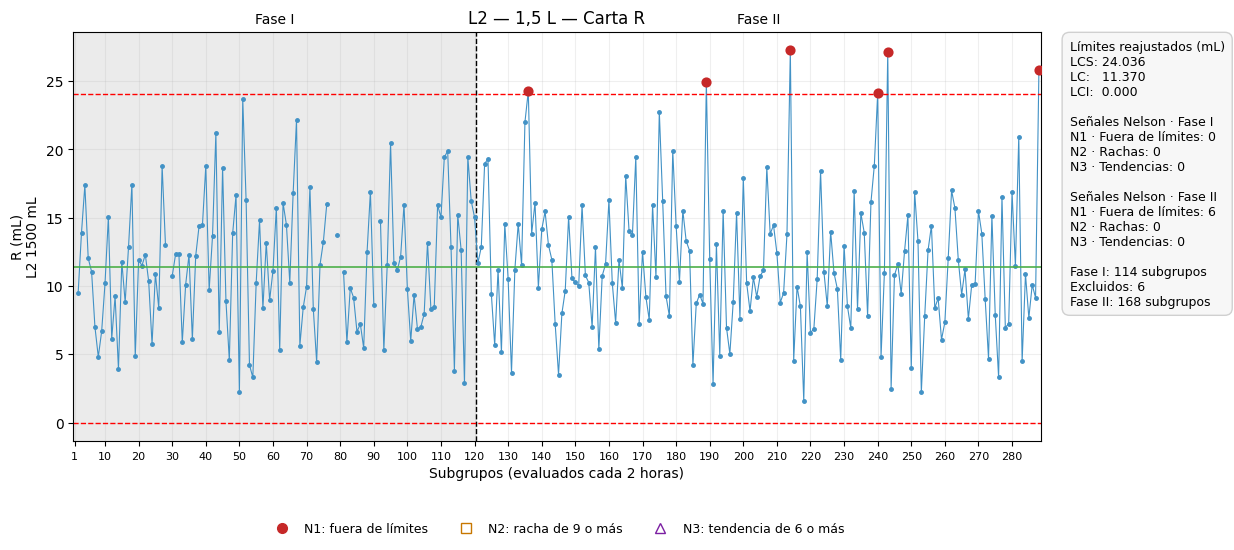

Fase I — Evidencia de las señales — L2 · 1,5 L — R: sin señales N1, N2 o N3.


Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N1 · Fuera de límites,Sobre LCS,136,C (22-06),5,FUN-B15,1
N1 · Fuera de límites,Sobre LCS,189,C (22-06),7,NEC-D15,1
N1 · Fuera de límites,Sobre LCS,214,C (22-06),8,CIT-L15,1
N1 · Fuera de límites,Sobre LCS,240,C (22-06),9,CIT-L15,1
N1 · Fuera de límites,Sobre LCS,243,A (06-14),9,NEC-D15,1
N1 · Fuera de límites,Sobre LCS,288,C (22-06),10,FUN-B15,1


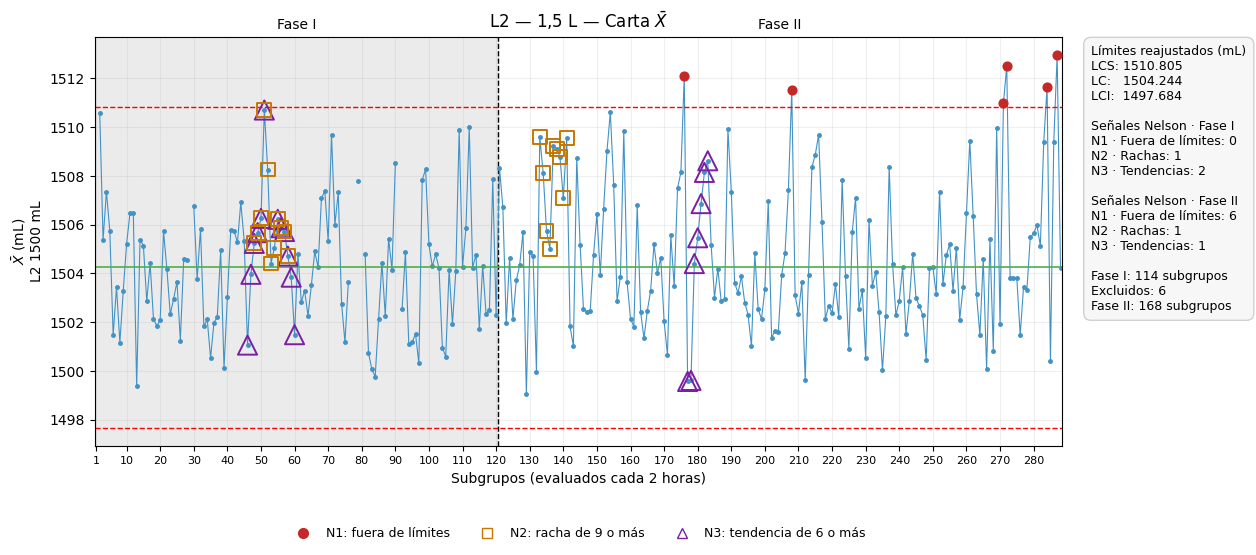

Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N3 · Tendencia,Creciente,"46, 47, 48",A (06-14),2,FUN-B15,3
N3 · Tendencia,Creciente,"49, 50, 51",C (22-06),2,FUN-B15,3
N2 · Racha,Sobre LC,48,A (06-14),2,FUN-B15,1
N2 · Racha,Sobre LC,"49, 50, 51, 52",C (22-06),2,FUN-B15,4
N2 · Racha,Sobre LC,"53, 54, 55, 56, 57, 58",A (06-14),3,CIT-L15,6
N3 · Tendencia,Decreciente,"55, 56, 57, 58, 59, 60",A (06-14),3,CIT-L15,6


Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N2 · Racha,Sobre LC,"133, 134, 135, 136",C (22-06),5,FUN-B15,4
N2 · Racha,Sobre LC,"137, 138, 139, 140",C (22-06),6,FUN-B15,4
N2 · Racha,Sobre LC,141,C (22-06),6,CIT-L15,1
N1 · Fuera de límites,Sobre LCS,176,C (22-06),7,NEC-D15,1
N3 · Tendencia,Creciente,"177, 178, 179, 180",A (06-14),7,NEC-D15,4
N3 · Tendencia,Creciente,"181, 182, 183",C (22-06),7,NEC-D15,3
N1 · Fuera de límites,Sobre LCS,208,C (22-06),8,FUN-B15,1
N1 · Fuera de límites,Sobre LCS,271,C (22-06),10,FUN-B15,1
N1 · Fuera de límites,Sobre LCS,272,C (22-06),10,FUN-B15,1
N1 · Fuera de límites,Sobre LCS,284,C (22-06),10,NEC-D15,1


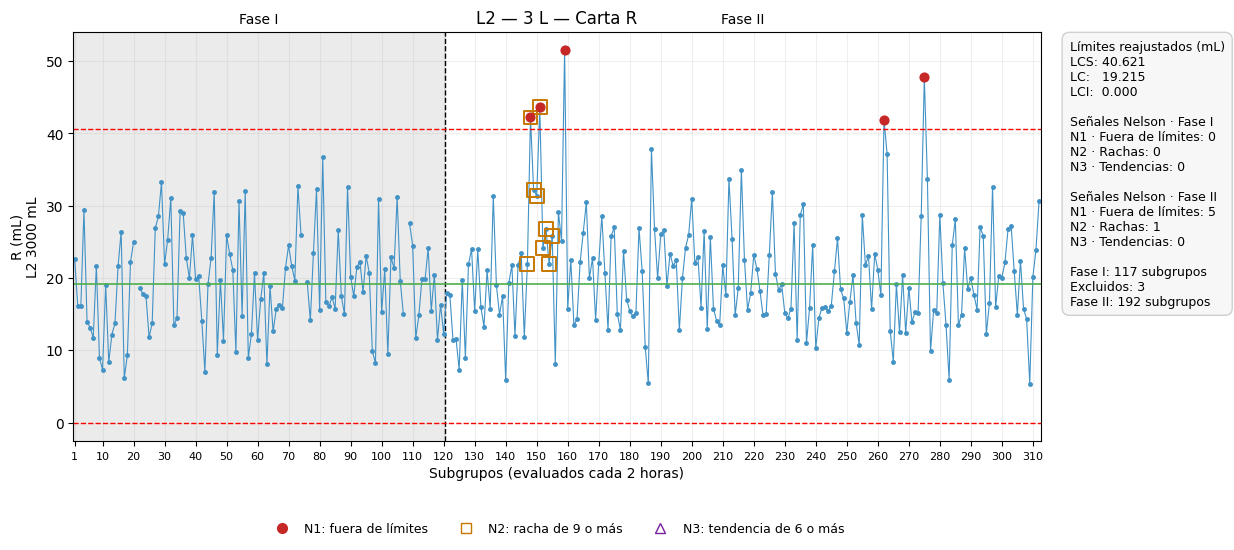

Fase I — Evidencia de las señales — L2 · 3 L — R: sin señales N1, N2 o N3.


Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N2 · Racha,Sobre LC,"147, 148",B (14-22),5,CIT-L30,2
N2 · Racha,Sobre LC,"149, 150, 151, 152",C (22-06),5,NEC-D30,4
N2 · Racha,Sobre LC,"153, 154, 155",A (06-14),5,NEC-D30,3
N1 · Fuera de límites,Sobre LCS,148,B (14-22),5,CIT-L30,1
N1 · Fuera de límites,Sobre LCS,151,C (22-06),5,NEC-D30,1
N1 · Fuera de límites,Sobre LCS,159,C (22-06),5,CIT-L30,1
N1 · Fuera de límites,Sobre LCS,262,B (14-22),8,NEC-D30,1
N1 · Fuera de límites,Sobre LCS,275,C (22-06),9,NEC-D30,1


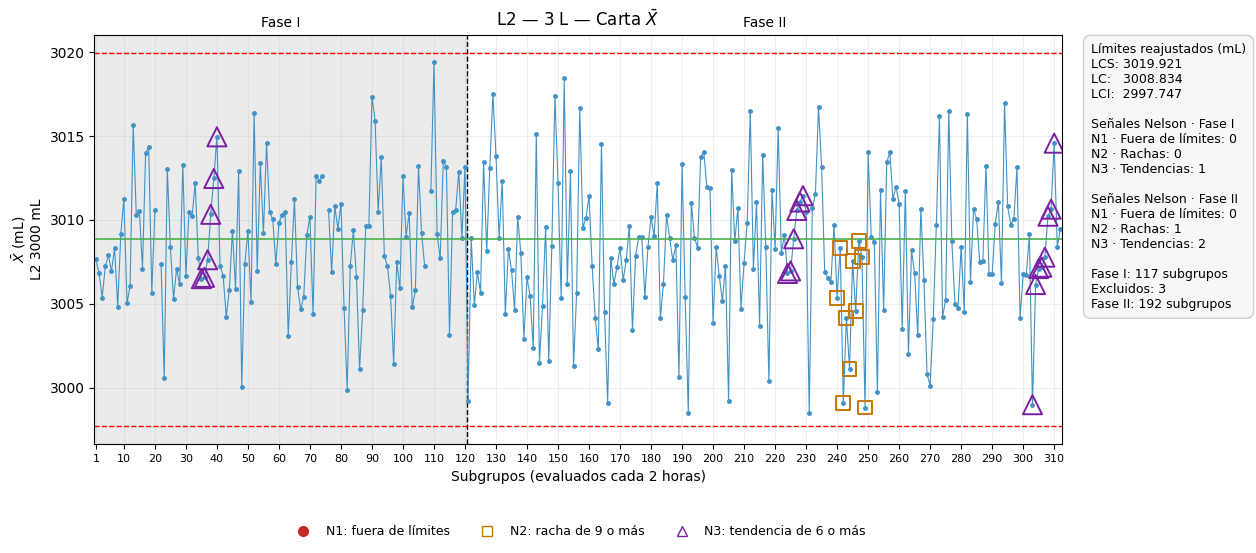

Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N3 · Tendencia,Creciente,"35, 36",B (14-22),1,NEC-D30,2
N3 · Tendencia,Creciente,"37, 38, 39, 40",C (22-06),1,NEC-D30,4


Señal,Sentido,Subgrupos,Turno,Semana,SKU,Cantidad
N3 · Tendencia,Creciente,224,B (14-22),7,NEC-D30,1
N3 · Tendencia,Creciente,"225, 226, 227, 228",A (06-14),7,CIT-L30,4
N3 · Tendencia,Creciente,229,A (06-14),8,CIT-L30,1
N2 · Racha,Bajo LC,240,A (06-14),8,CIT-L30,1
N2 · Racha,Bajo LC,"241, 242, 243, 244",B (14-22),8,CIT-L30,4
N2 · Racha,Bajo LC,"245, 246, 247, 248",C (22-06),8,CIT-L30,4
N2 · Racha,Bajo LC,249,A (06-14),8,NEC-D30,1
N3 · Tendencia,Creciente,"303, 304, 309, 310",B (14-22),10,CIT-L30,4
N3 · Tendencia,Creciente,"305, 306, 307, 308",A (06-14),10,CIT-L30,4



La Fase I reajustada todavía presenta señales. Los límites se mantienen provisionales. No se excluyeron automáticamente otros subgrupos.


In [8]:
# ==================================================
# A.2. CARTAS ORIGINALES + NELSON + CONTEXTO DE SEÑALES
# ==================================================
# Utiliza "resultados" de las secciones anteriores.
# No modifica datos, límites ni subgrupos.
#
# N1: un punto fuera de los límites de la carta.
# N2: nueve puntos consecutivos al mismo lado de la LC.
# N3: seis puntos consecutivos crecientes o decrecientes.
#
# Las reglas se evalúan únicamente en Fase I.
# ==================================================


# --------------------------------------------------
# 7.1. DETECTAR LAS SEÑALES
# --------------------------------------------------

def senales_fase1_original(base, columna, LCI, LC, LCS):

    base = base.sort_values(
        "numero_subgrupo"
    ).reset_index(drop=True)

    detecciones = []

    for i in range(len(base)):

        numero = int(base.loc[i, "numero_subgrupo"])
        valor = base.loc[i, columna]

        # N1: punto fuera de los límites.
        if valor < LCI or valor > LCS:

            detecciones.append({
                "regla": "N1",
                "inicio": numero,
                "final": numero,
                "sentido": "Sobre LCS" if valor > LCS else "Bajo LCI"
            })

        # N2: nueve puntos al mismo lado de la LC.
        if i >= 8:

            ventana = base.iloc[i - 8:i + 1]

            consecutivos = (
                ventana["numero_subgrupo"]
                .diff().iloc[1:].eq(1).all()
            )

            sobre = (ventana[columna] > LC).all()
            bajo = (ventana[columna] < LC).all()

            if consecutivos and (sobre or bajo):

                detecciones.append({
                    "regla": "N2",
                    "inicio": int(
                        ventana["numero_subgrupo"].iloc[0]
                    ),
                    "final": numero,
                    "sentido": "Sobre LC" if sobre else "Bajo LC"
                })

        # N3: seis puntos crecientes o decrecientes.
        if i >= 5:

            ventana = base.iloc[i - 5:i + 1]

            consecutivos = (
                ventana["numero_subgrupo"]
                .diff().iloc[1:].eq(1).all()
            )

            diferencias = ventana[columna].diff().iloc[1:]

            creciente = (diferencias > 0).all()
            decreciente = (diferencias < 0).all()

            if consecutivos and (creciente or decreciente):

                detecciones.append({
                    "regla": "N3",
                    "inicio": int(
                        ventana["numero_subgrupo"].iloc[0]
                    ),
                    "final": numero,
                    "sentido": (
                        "Creciente" if creciente else "Decreciente"
                    )
                })

    # Reunir ventanas superpuestas de una misma secuencia.
    # Una racha prolongada cuenta como una sola racha.
    señales = []

    for regla in ["N1", "N2", "N3"]:

        sentidos = sorted({
            d["sentido"]
            for d in detecciones
            if d["regla"] == regla
        })

        for sentido in sentidos:

            seleccion = sorted(
                [
                    d for d in detecciones
                    if d["regla"] == regla
                    and d["sentido"] == sentido
                ],
                key=lambda d: d["inicio"]
            )

            actual = None

            for deteccion in seleccion:

                if actual is None:
                    actual = deteccion.copy()

                elif (
                    regla != "N1"
                    and deteccion["inicio"] <= actual["final"]
                ):

                    actual["final"] = max(
                        actual["final"],
                        deteccion["final"]
                    )

                else:
                    señales.append(actual)
                    actual = deteccion.copy()

            if actual is not None:
                señales.append(actual)

    return sorted(
        señales,
        key=lambda señal: (señal["inicio"], señal["regla"])
    )

# --------------------------------------------------
# 7.2. MOSTRAR SOLO LA EVIDENCIA DE CADA SEÑAL
# --------------------------------------------------

def mostrar_contexto_original(datos, fase1, señales, linea, formato, carta):

    if not señales:
        print("Fase I: sin señales de N1, N2 o N3.")
        return pd.DataFrame()

    nombres = {
        "N1": "N1 · Fuera de límites",
        "N2": "N2 · Racha",
        "N3": "N3 · Tendencia"
    }

    filas = []

    for señal in señales:

        tramo = fase1[
            fase1["numero_subgrupo"].between(
                señal["inicio"], señal["final"]
            )
        ].sort_values("numero_subgrupo")

        grupos_contexto = tramo.groupby(
            ["turno", "semana_registro", "sku"],
            sort=False,
            dropna=False
        )

        for (turno, semana, sku), grupo in grupos_contexto:

            numeros = ", ".join(
                str(int(numero))
                for numero in grupo["numero_subgrupo"]
            )

            filas.append({
                "Señal": nombres[señal["regla"]],
                "Sentido": señal["sentido"],
                "Subgrupos": numeros,
                "Turno": turno,
                "Semana": semana,
                "SKU": sku,
                "Cantidad": len(grupo)
            })

    tabla = pd.DataFrame(filas)

    estilo = """
    <style>
    .contexto-original {
        overflow-x: auto;
        background: transparent !important;
        color: inherit !important;
        margin-bottom: 15px;
    }

    .contexto-original table {
        border-collapse: collapse;
        width: 100%;
        font-size: 13px;
    }

    .contexto-original table,
    .contexto-original thead,
    .contexto-original tbody,
    .contexto-original tr,
    .contexto-original th,
    .contexto-original td {
        background: transparent !important;
        color: inherit !important;
    }

    .contexto-original th,
    .contexto-original td {
        border: 1px solid currentColor !important;
        padding: 7px;
        text-align: center !important;
    }
    </style>
    """

    display(HTML(
        estilo
        + '<div class="contexto-original">'
                + (
            f"<h4>Fase I — Evidencia de las señales — "
            f"{linea} — {str(formato).replace('.', ',')} L - "
            f"{'R' if carta == 'R' else 'X̄'}</h4>"
        )
        + tabla.to_html(
            index=False,
            border=0,
            escape=True
        )
        + "</div>"
    ))

    return tabla


# --------------------------------------------------
# 7.3. CONFIGURACIÓN DE LAS MARCAS
# --------------------------------------------------

colores_nelson = {
    "N1": "#C62828",
    "N2": "#C77700",
    "N3": "#7B1FA2"
}

figuras_nelson = {
    "N1": "o",
    "N2": "s",
    "N3": "^"
}

tamanos_nelson = {
    "N1": 35,
    "N2": 100,
    "N3": 190
}

# Guardar los resultados para el análisis del informe.
senales_originales_fase1 = {}
contextos_originales_fase1 = {}


# --------------------------------------------------
# 7.4. GRAFICAR Y MOSTRAR EL CONTEXTO INMEDIATAMENTE
# --------------------------------------------------

for linea, formato in combinaciones:

    resultado = resultados[(linea, formato)]

    datos = resultado["datos"].sort_values(
        "numero_subgrupo"
    )

    fase1 = resultado["fase1"].sort_values(
        "numero_subgrupo"
    )

    fase2 = resultado["fase2"]

    ultimo_fase1 = int(fase1["numero_subgrupo"].max())
    total_subgrupos = len(datos)

    volumen = f"{formato:g}".replace(".", ",")
    volumen_ml = int(formato * 1000)

    # Primero R y después X barra.
    for carta in ["R", "X"]:

        if carta == "R":

            columna = "rango"
            simbolo = "R"
            LCI = resultado["LCI_R"]
            LC = resultado["LC_R"]
            LCS = resultado["LCS_R"]

        else:

            columna = "promedio"
            simbolo = r"$\bar{X}$"
            LCI = resultado["LCI_X"]
            LC = resultado["LC_X"]
            LCS = resultado["LCS_X"]

        valores = datos[columna]

        señales = senales_fase1_original(
            fase1, columna, LCI, LC, LCS
        )

        clave = (linea, formato, carta)
        senales_originales_fase1[clave] = señales

        cantidades = {
            regla: sum(
                señal["regla"] == regla
                for señal in señales
            )
            for regla in ["N1", "N2", "N3"]
        }

        fig, ax = plt.subplots(figsize=(15, 6))

        fig.subplots_adjust(
            right=0.77,
            bottom=0.23,
            top=0.86
        )

        # Sombrear Fase I.
        ax.axvspan(
            0.5,
            ultimo_fase1 + 0.5,
            color="#E6E6E6",
            alpha=0.8
        )

        # Separar las fases.
        ax.axvline(
            ultimo_fase1 + 0.5,
            color="black",
            linestyle="--",
            linewidth=1
        )

        # Datos originales.
        ax.plot(
            datos["numero_subgrupo"],
            valores,
            color="#4292C6",
            marker="o",
            markersize=2.5,
            linewidth=0.8,
            zorder=2
        )

        # Límites originales de prueba.
        ax.axhline(
            LCS,
            color="red",
            linestyle="--",
            linewidth=1
        )

        ax.axhline(
            LC,
            color="#4DAF4A",
            linewidth=1.2
        )

        ax.axhline(
            LCI,
            color="red",
            linestyle="--",
            linewidth=1
        )

        # Marcar las señales de Fase I.
        # Las figuras grandes se dibujan primero.
        for regla in ["N3", "N2", "N1"]:

            participantes = set()

            for señal in señales:

                if señal["regla"] == regla:

                    tramo = fase1[
                        fase1["numero_subgrupo"].between(
                            señal["inicio"],
                            señal["final"]
                        )
                    ]

                    participantes.update(
                        tramo["numero_subgrupo"]
                    )

            puntos = fase1[
                fase1["numero_subgrupo"].isin(participantes)
            ]

            if puntos.empty:
                continue

            ax.scatter(
                puntos["numero_subgrupo"],
                puntos[columna],
                marker=figuras_nelson[regla],
                s=tamanos_nelson[regla],
                facecolors=(
                    colores_nelson[regla]
                    if regla == "N1"
                    else "none"
                ),
                edgecolors=colores_nelson[regla],
                linewidths=1.4,
                zorder={"N3": 3, "N2": 4, "N1": 5}[regla]
            )

        # Título y nombres de ejes.
        ax.set_title(
            f"{linea} — {volumen} L — Carta {simbolo}",
            fontsize=12
        )

        ax.set_xlabel(
            "Subgrupos (evaluados cada 2 horas)",
            fontsize=10
        )

        ax.set_ylabel(
            f"{simbolo} (mL)\n{linea} {volumen_ml} mL",
            fontsize=10
        )

        marcas = [1] + list(
            range(10, total_subgrupos + 1, 10)
        )

        ax.set_xticks(marcas)

        ax.tick_params(
            axis="x",
            labelrotation=0,
            labelsize=8
        )

        ax.set_xlim(0.5, total_subgrupos + 0.5)
        ax.grid(True, alpha=0.2)

        # Identificar las fases.
        ax.text(
            (1 + ultimo_fase1) / 2,
            1.02,
            "Fase I",
            transform=ax.get_xaxis_transform(),
            ha="center",
            fontsize=10
        )

        if len(fase2) > 0:

            ax.text(
                (ultimo_fase1 + 1 + total_subgrupos) / 2,
                1.02,
                "Fase II",
                transform=ax.get_xaxis_transform(),
                ha="center",
                fontsize=10
            )

        # Resumen lateral: límites y señales.
        texto = (
            "Límites de prueba (mL)\n"
            f"LCS: {LCS:.3f}\n"
            f"LC:   {LC:.3f}\n"
            f"LCI:  {LCI:.3f}\n\n"
            "Señales Nelson · Fase I\n"
            f"N1 · Fuera de límites: {cantidades['N1']}\n"
            f"N2 · Rachas: {cantidades['N2']}\n"
            f"N3 · Tendencias: {cantidades['N3']}\n\n"
            "Fase I · semanas 1–4\n"
            f"{len(fase1)} subgrupos\n"
            f"Subgrupos 1–{ultimo_fase1}\n\n"
            "Fase II · desde semana 5\n"
            f"{len(fase2)} subgrupos"
        )

        ax.text(
            1.03,
            0.98,
            texto,
            transform=ax.transAxes,
            va="top",
            fontsize=9,
            linespacing=1.3,
            bbox={
                "boxstyle": "round,pad=0.6",
                "facecolor": "#F7F7F7",
                "edgecolor": "#D0D0D0"
            }
        )

        # Leyenda.
        leyenda = [
            Line2D(
                [0], [0],
                marker="o",
                linestyle="none",
                color=colores_nelson["N1"],
                markersize=6,
                label="N1: fuera de límites"
            ),
            Line2D(
                [0], [0],
                marker="s",
                linestyle="none",
                markeredgecolor=colores_nelson["N2"],
                markerfacecolor="none",
                markersize=8,
                label="N2: 9 o más al mismo lado de LC"
            ),
            Line2D(
                [0], [0],
                marker="^",
                linestyle="none",
                markeredgecolor=colores_nelson["N3"],
                markerfacecolor="none",
                markersize=9,
                label="N3: 6 o más crecientes/decrecientes"
            )
        ]

        ax.legend(
            handles=leyenda,
            loc="upper center",
            bbox_to_anchor=(0.5, -0.17),
            ncol=3,
            frameon=False,
            fontsize=8
        )

        plt.show()

        # Contexto inmediatamente debajo de ESTE gráfico.
        contextos_originales_fase1[clave] = (
            mostrar_contexto_original(
                datos,
                fase1,
                señales,
                linea,
                formato,
                carta
            )
        )


# ============================================================
# 1. EXCLUSIONES ACORDADAS
# Numeración de subgrupos utilizada en los gráficos.
# ============================================================

combinaciones = [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]

exclusiones_reajuste = {
    ("L1", 0.5): [],
    ("L2", 1.5): [1, 29, 77, 78, 80, 91],
    ("L2", 3.0): [21, 75, 108]
}

A2 = 0.577
D3 = 0
D4 = 2.114


# ============================================================
# 2. DETECTAR NELSON
# Se aplica por separado a cada fase.
# ============================================================

def detectar_nelson_reajuste(base, columna, lci, lc, lcs):

    base = (
        base.sort_values("numero_subgrupo")
        .reset_index(drop=True)
    )

    detecciones = []

    for i in range(len(base)):

        numero = int(base.loc[i, "numero_subgrupo"])
        valor = base.loc[i, columna]

        # N1: punto fuera de los límites.
        if valor < lci or valor > lcs:

            detecciones.append({
                "regla": "N1",
                "inicio": numero,
                "final": numero,
                "sentido": "Sobre LCS" if valor > lcs else "Bajo LCI"
            })

        # N2 y N3.
        for regla, longitud in [("N2", 9), ("N3", 6)]:

            if i < longitud - 1:
                continue

            ventana = base.iloc[i - longitud + 1:i + 1]

            # No unir secuencias a través de subgrupos excluidos.
            consecutivos = (
                ventana["numero_subgrupo"]
                .diff().iloc[1:].eq(1).all()
            )

            if not consecutivos:
                continue

            valores = ventana[columna]
            sentido = None

            if regla == "N2":

                if (valores > lc).all():
                    sentido = "Sobre LC"
                elif (valores < lc).all():
                    sentido = "Bajo LC"

            else:

                diferencias = valores.diff().iloc[1:]

                if (diferencias > 0).all():
                    sentido = "Creciente"
                elif (diferencias < 0).all():
                    sentido = "Decreciente"

            if sentido is not None:

                detecciones.append({
                    "regla": regla,
                    "inicio": int(
                        ventana["numero_subgrupo"].iloc[0]
                    ),
                    "final": numero,
                    "sentido": sentido
                })

    # Reunir ventanas superpuestas de una misma secuencia.
    señales = []

    for regla in ["N1", "N2", "N3"]:

        sentidos = sorted({
            d["sentido"]
            for d in detecciones
            if d["regla"] == regla
        })

        for sentido in sentidos:

            grupo = sorted(
                [
                    d for d in detecciones
                    if d["regla"] == regla
                    and d["sentido"] == sentido
                ],
                key=lambda d: d["inicio"]
            )

            actual = None

            for deteccion in grupo:

                if actual is None:
                    actual = deteccion.copy()

                elif (
                    regla != "N1"
                    and deteccion["inicio"] <= actual["final"]
                ):

                    actual["final"] = max(
                        actual["final"],
                        deteccion["final"]
                    )

                else:
                    señales.append(actual)
                    actual = deteccion.copy()

            if actual is not None:
                señales.append(actual)

    return sorted(
        señales,
        key=lambda s: (s["inicio"], s["regla"])
    )


# ============================================================
# 3. MOSTRAR TABLAS
# ============================================================

def mostrar_tabla_reajuste(titulo, tabla):

    estilo = """
    <style>
    .tabla-reajuste {
        overflow-x: auto;
        background: transparent !important;
        color: inherit !important;
        margin-bottom: 20px;
    }

    .tabla-reajuste table {
        border-collapse: collapse;
        width: 100%;
        font-size: 13px;
    }

    .tabla-reajuste table,
    .tabla-reajuste thead,
    .tabla-reajuste tbody,
    .tabla-reajuste tr,
    .tabla-reajuste th,
    .tabla-reajuste td {
        background: transparent !important;
        color: inherit !important;
    }

    .tabla-reajuste th,
    .tabla-reajuste td {
        border: 1px solid currentColor !important;
        padding: 7px;
        text-align: center !important;
    }
    </style>
    """

    display(HTML(
        estilo
        + '<div class="tabla-reajuste">'
        + f"<h4>{titulo}</h4>"
        + tabla.to_html(index=False, border=0, escape=True)
        + "</div>"
    ))


# ============================================================
# 4. RECALCULAR LOS LÍMITES
# Solo se utiliza la Fase I que queda tras las exclusiones.
# ============================================================

resultados_ajustados = {}
filas_resumen = []
filas_limites = []

for linea, formato in combinaciones:

    clave = (linea, formato)
    original = resultados[clave]
    excluidos = exclusiones_reajuste[clave]

    fase1 = original["fase1"][
        ~original["fase1"]["numero_subgrupo"].isin(excluidos)
    ].copy()

    # Fase II se conserva completa.
    fase2 = original["fase2"].copy()

    R_barra = fase1["rango"].mean()
    X_barra_barra = fase1["promedio"].mean()

    LCI_R = D3 * R_barra
    LC_R = R_barra
    LCS_R = D4 * R_barra

    LCI_X = X_barra_barra - A2 * R_barra
    LC_X = X_barra_barra
    LCS_X = X_barra_barra + A2 * R_barra

    resultados_ajustados[clave] = {
        "datos": original["datos"].copy(),
        "fase1": fase1,
        "fase2": fase2,
        "excluidos": excluidos.copy(),
        "LCI_R": LCI_R,
        "LC_R": LC_R,
        "LCS_R": LCS_R,
        "LCI_X": LCI_X,
        "LC_X": LC_X,
        "LCS_X": LCS_X
    }

    volumen = f"{formato:g}".replace(".", ",")
    nombre = f"{linea} — {volumen} L"

    filas_resumen.append({
        "Línea y volumen": nombre,
        "Fase I inicial": len(original["fase1"]),
        "Subgrupos excluidos": (
            ", ".join(str(n) for n in excluidos)
            if excluidos else "—"
        ),
        "Fase I conservada": len(fase1),
        "Fase II": len(fase2)
    })

    filas_limites.append({
        "Línea y volumen": nombre,
        "LCI R": f"{LCI_R:.3f}",
        "LC R": f"{LC_R:.3f}",
        "LCS R": f"{LCS_R:.3f}",
        "LCI X̄": f"{LCI_X:.3f}",
        "LC X̄": f"{LC_X:.3f}",
        "LCS X̄": f"{LCS_X:.3f}"
    })

resumen_reajuste = pd.DataFrame(filas_resumen)
limites_reajuste = pd.DataFrame(filas_limites)

mostrar_tabla_reajuste(
    "Resumen del reajuste — Fase I: semanas 1 a 4",
    resumen_reajuste
)

mostrar_tabla_reajuste(
    "Límites reajustados (mL)",
    limites_reajuste
)


# ============================================================
# 5. EVIDENCIA DE LAS SEÑALES
# ============================================================

def crear_evidencia_reajuste(base, señales):

    nombres = {
        "N1": "N1 · Fuera de límites",
        "N2": "N2 · Racha",
        "N3": "N3 · Tendencia"
    }

    filas = []

    for señal in señales:

        tramo = base[
            base["numero_subgrupo"].between(
                señal["inicio"], señal["final"]
            )
        ].sort_values("numero_subgrupo")

        grupos = tramo.groupby(
            ["turno", "semana_registro", "sku"],
            sort=False,
            dropna=False
        )

        for (turno, semana, sku), grupo in grupos:

            filas.append({
                "Señal": nombres[señal["regla"]],
                "Sentido": señal["sentido"],
                "Subgrupos": ", ".join(
                    str(int(n))
                    for n in grupo["numero_subgrupo"]
                ),
                "Turno": turno,
                "Semana": semana,
                "SKU": sku,
                "Cantidad": len(grupo)
            })

    return pd.DataFrame(
        filas,
        columns=[
            "Señal", "Sentido", "Subgrupos",
            "Turno", "Semana", "SKU", "Cantidad"
        ]
    )


# ============================================================
# 6. GRÁFICOS Y TABLAS DE AMBAS FASES
# ============================================================

colores = {
    "N1": "#C62828",
    "N2": "#C77700",
    "N3": "#7B1FA2"
}

marcadores = {"N1": "o", "N2": "s", "N3": "^"}
tamanos = {"N1": 35, "N2": 100, "N3": 190}

senales_reajustadas = {}
contextos_reajustados = {}
filas_verificacion = []

for linea, formato in combinaciones:

    clave = (linea, formato)
    resultado = resultados_ajustados[clave]

    datos = resultado["datos"].sort_values(
        "numero_subgrupo"
    ).copy()

    fase1 = resultado["fase1"]
    fase2 = resultado["fase2"]

    corte = int(
        resultados[clave]["fase1"]["numero_subgrupo"].max()
    )

    ultimo = int(datos["numero_subgrupo"].max())

    volumen = f"{formato:g}".replace(".", ",")
    volumen_ml = int(formato * 1000)

    for carta in ["R", "X"]:

        columna = "rango" if carta == "R" else "promedio"
        simbolo = "R" if carta == "R" else r"$\bar{X}$"
        simbolo_tabla = "R" if carta == "R" else "X̄"

        lci = resultado[f"LCI_{carta}"]
        lc = resultado[f"LC_{carta}"]
        lcs = resultado[f"LCS_{carta}"]

        señales_I = detectar_nelson_reajuste(
            fase1, columna, lci, lc, lcs
        )

        señales_II = detectar_nelson_reajuste(
            fase2, columna, lci, lc, lcs
        )

        senales_reajustadas[
            (linea, formato, carta, "I")
        ] = señales_I

        senales_reajustadas[
            (linea, formato, carta, "II")
        ] = señales_II

        for señal in señales_I:

            filas_verificacion.append({
                "Línea": linea,
                "Litros": formato,
                "Carta": simbolo_tabla,
                "Regla": señal["regla"],
                "Inicio": señal["inicio"],
                "Final": señal["final"]
            })

        conteos_I = {
            regla: sum(s["regla"] == regla for s in señales_I)
            for regla in ["N1", "N2", "N3"]
        }

        conteos_II = {
            regla: sum(s["regla"] == regla for s in señales_II)
            for regla in ["N1", "N2", "N3"]
        }

        # Mantener espacios donde se excluyeron subgrupos.
        valores = datos[columna].copy()

        valores.loc[
            datos["numero_subgrupo"].isin(
                resultado["excluidos"]
            )
        ] = float("nan")

        fig, ax = plt.subplots(figsize=(15, 6.5))

        fig.subplots_adjust(
            right=0.77,
            bottom=0.23,
            top=0.86
        )

        ax.axvspan(
            0.5, corte + 0.5,
            color="#E6E6E6", alpha=0.8
        )

        ax.axvline(
            corte + 0.5,
            color="black",
            linestyle="--",
            linewidth=1
        )

        ax.plot(
            datos["numero_subgrupo"],
            valores,
            color="#4292C6",
            marker="o",
            markersize=2.5,
            linewidth=0.8
        )

        ax.axhline(
            lcs, color="red", linestyle="--", linewidth=1
        )

        ax.axhline(
            lc, color="#4DAF4A", linewidth=1.2
        )

        ax.axhline(
            lci, color="red", linestyle="--", linewidth=1
        )

        # Marcar señales en ambas fases, por separado.
        for base, señales in [
            (fase1, señales_I),
            (fase2, señales_II)
        ]:

            for regla in ["N3", "N2", "N1"]:

                participantes = set()

                for señal in señales:

                    if señal["regla"] == regla:

                        tramo = base[
                            base["numero_subgrupo"].between(
                                señal["inicio"],
                                señal["final"]
                            )
                        ]

                        participantes.update(
                            tramo["numero_subgrupo"]
                        )

                puntos = base[
                    base["numero_subgrupo"].isin(participantes)
                ]

                if puntos.empty:
                    continue

                ax.scatter(
                    puntos["numero_subgrupo"],
                    puntos[columna],
                    marker=marcadores[regla],
                    s=tamanos[regla],
                    facecolors=(
                        colores[regla]
                        if regla == "N1"
                        else "none"
                    ),
                    edgecolors=colores[regla],
                    linewidths=1.4,
                    zorder={"N3": 3, "N2": 4, "N1": 5}[regla]
                )

        ax.set_title(
            f"{linea} — {volumen} L — Carta {simbolo}",
            fontsize=12
        )

        ax.set_xlabel(
            "Subgrupos (evaluados cada 2 horas)"
        )

        ax.set_ylabel(
            f"{simbolo} (mL)\n{linea} {volumen_ml} mL"
        )

        ax.set_xticks(
            [1] + list(range(10, ultimo + 1, 10))
        )

        ax.tick_params(
            axis="x", labelrotation=0, labelsize=8
        )

        ax.set_xlim(0.5, ultimo + 0.5)
        ax.grid(True, alpha=0.2)

        ax.text(
            (1 + corte) / 2,
            1.02,
            "Fase I",
            transform=ax.get_xaxis_transform(),
            ha="center"
        )

        if len(fase2) > 0:

            ax.text(
                (corte + 1 + ultimo) / 2,
                1.02,
                "Fase II",
                transform=ax.get_xaxis_transform(),
                ha="center"
            )

        texto = (
            "Límites reajustados (mL)\n"
            f"LCS: {lcs:.3f}\n"
            f"LC:   {lc:.3f}\n"
            f"LCI:  {lci:.3f}\n\n"
            "Señales Nelson · Fase I\n"
            f"N1 · Fuera de límites: {conteos_I['N1']}\n"
            f"N2 · Rachas: {conteos_I['N2']}\n"
            f"N3 · Tendencias: {conteos_I['N3']}\n\n"
            "Señales Nelson · Fase II\n"
            f"N1 · Fuera de límites: {conteos_II['N1']}\n"
            f"N2 · Rachas: {conteos_II['N2']}\n"
            f"N3 · Tendencias: {conteos_II['N3']}\n\n"
            f"Fase I: {len(fase1)} subgrupos\n"
            f"Excluidos: {len(resultado['excluidos'])}\n"
            f"Fase II: {len(fase2)} subgrupos"
        )

        ax.text(
            1.03, 0.98,
            texto,
            transform=ax.transAxes,
            va="top",
            fontsize=9,
            linespacing=1.2,
            bbox={
                "boxstyle": "round,pad=0.6",
                "facecolor": "#F7F7F7",
                "edgecolor": "#D0D0D0"
            }
        )

        etiquetas = {
            "N1": "N1: fuera de límites",
            "N2": "N2: racha de 9 o más",
            "N3": "N3: tendencia de 6 o más"
        }

        leyenda = [
            Line2D(
                [0], [0],
                marker=marcadores[regla],
                linestyle="none",
                markeredgecolor=colores[regla],
                markerfacecolor=(
                    colores[regla]
                    if regla == "N1"
                    else "none"
                ),
                markersize=7,
                label=etiquetas[regla]
            )
            for regla in ["N1", "N2", "N3"]
        ]

        ax.legend(
            handles=leyenda,
            loc="upper center",
            bbox_to_anchor=(0.5, -0.17),
            ncol=3,
            frameon=False,
            fontsize=9
        )

        plt.show()

        # Tablas de evidencia debajo de cada gráfico.
        for fase, base, señales in [
            ("I", fase1, señales_I),
            ("II", fase2, señales_II)
        ]:

            tabla = crear_evidencia_reajuste(base, señales)

            contextos_reajustados[
                (linea, formato, carta, fase)
            ] = tabla

            titulo = (
                f"Fase {fase} — Evidencia de las señales — "
                f"{linea} · {volumen} L — {simbolo_tabla}"
            )

            if tabla.empty:
                print(
                    f"{titulo}: sin señales N1, N2 o N3."
                )
            else:
                mostrar_tabla_reajuste(titulo, tabla)

        print()


# ============================================================
# 7. RESULTADO DE LA VERIFICACIÓN DE FASE I
# ============================================================

verificacion_fase1_reajustada = pd.DataFrame(
    filas_verificacion,
    columns=[
        "Línea", "Litros", "Carta",
        "Regla", "Inicio", "Final"
    ]
)

if verificacion_fase1_reajustada.empty:

    print(
        "Fase I: no se detectaron señales "
        "con las tres reglas seleccionadas."
    )

else:

    print(
        "La Fase I reajustada todavía presenta señales. "
        "Los límites se mantienen provisionales. "
        "No se excluyeron automáticamente otros subgrupos."
    )


In [6]:
# ============================================================
# A.3. CAPACIDAD, DESEMPEÑO Y VERIFICACIÓN DE CONTENIDO
# ============================================================
# Cp/Cpk:
#   Fase I conservada en resultados_ajustados.
#
# Pp/Ppk y verificación de contenido:
#   Todas las botellas originales de las semanas 1 a 10.
#
# Resultados globales y por turno, para cada línea × formato.
# ============================================================


# ------------------------------------------------------------
# 1. LEER LOS DATOS
# ------------------------------------------------------------


datos_capacidad = pd.read_csv(
    ruta_base + "calidad_llenado.csv"
)

especificaciones = pd.read_csv(
    ruta_base + "especificaciones_calidad.csv"
)

datos_capacidad = datos_capacidad[
    datos_capacidad["semana_registro"].between(1, 10)
].copy()

if "resultados_ajustados" not in globals():
    raise ValueError(
        "Primero ejecuta el código del reajuste "
        "que crea resultados_ajustados."
    )

combinaciones_capacidad = [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]

# Constante tabulada para cinco botellas por subgrupo.
d2 = 2.326

# Referencia adoptada para los índices.
objetivo_indice = 1.33

# Convención visual para ≈ y comparación de turnos.
diferencia_visual = 0.05


# ------------------------------------------------------------
# 2. FORMATO NUMÉRICO Y COMPARACIONES
# ------------------------------------------------------------

def numero_visible(valor):

    if pd.isna(valor):
        return "—"

    return f"{valor:.3f}".rstrip("0").rstrip(".")


def intervalo_indice(nombre, valor):

    if pd.isna(valor):
        return f"{nombre}: no calculable"

    if valor < 1:
        return f"{nombre} < 1"

    if valor < objetivo_indice:
        return f"1 ≤ {nombre} < 1.33"

    return f"{nombre} ≥ 1.33"


def comparar_indices(Cpk, Ppk):

    if pd.isna(Cpk) or pd.isna(Ppk):
        return "No calculable"

    if abs(Ppk - Cpk) <= diferencia_visual:
        return "Ppk ≈ Cpk"

    if Ppk < Cpk:
        return "Ppk < Cpk"

    return "Ppk > Cpk"


# ------------------------------------------------------------
# 3. CALCULAR CAPACIDAD, DESEMPEÑO Y CONTENIDO
# ------------------------------------------------------------

filas_indices = []
filas_oiml = []
filas_respaldo = []
notas_umbrales = []

for linea, formato in combinaciones_capacidad:

    especificacion = especificaciones[
        especificaciones["formato_L"] == formato
    ].iloc[0]

    nominal = float(especificacion["nominal_mL"])
    LIE = float(especificacion["LIE_mL"])
    LSE = float(especificacion["LSE_mL"])

    T_archivo = float(
        especificacion["tolerancia_oiml_mL"]
    )

    # Redondear la tolerancia hacia arriba.
    if nominal > 1000:
        T_aplicada = math.ceil(T_archivo)
    else:
        T_aplicada = math.ceil(T_archivo * 10) / 10

    umbral_T = nominal - T_aplicada
    umbral_2T = nominal - 2 * T_aplicada

    notas_umbrales.append(
        f"{formato:g} L: "
        f"T = {numero_visible(T_aplicada)} mL; "
        f"Qn−T = {numero_visible(umbral_T)} mL; "
        f"Qn−2T = {numero_visible(umbral_2T)} mL."
    )

    # Capacidad: Fase I del último reajuste ejecutado.
    fase1 = resultados_ajustados[
        (linea, formato)
    ]["fase1"].copy()

    if not fase1["botellas"].eq(5).all():
        raise ValueError(
            f"{linea}, {formato} L: existen subgrupos "
            "con tamaño distinto de cinco."
        )

    # Desempeño y contenido: todas las mediciones originales.
    originales = datos_capacidad[
        (datos_capacidad["linea"] == linea)
        & (datos_capacidad["formato_L"] == formato)
    ].copy()

    turnos = sorted(
        originales["turno"].dropna().unique()
    )

    for turno in ["Global"] + turnos:

        if turno == "Global":

            base_fase1 = fase1
            base_original = originales

        else:

            base_fase1 = fase1[
                fase1["turno"] == turno
            ]

            base_original = originales[
                originales["turno"] == turno
            ]

        # ----------------------------------------
        # Cp y Cpk: Fase I conservada.
        # ----------------------------------------

        media_fase1 = base_fase1["promedio"].mean()
        R_barra = base_fase1["rango"].mean()
        sigma_dentro = R_barra / d2

        if pd.notna(sigma_dentro) and sigma_dentro > 0:

            Cp = (LSE - LIE) / (6 * sigma_dentro)

            Cpk = min(
                (LSE - media_fase1) / (3 * sigma_dentro),
                (media_fase1 - LIE) / (3 * sigma_dentro)
            )

        else:

            Cp = float("nan")
            Cpk = float("nan")

        # ----------------------------------------
        # Pp y Ppk: diez semanas originales.
        # ----------------------------------------

        volumenes = base_original["volumen_mL"]

        cantidad = len(volumenes)
        media_global = volumenes.mean()

        # Desviación muestral de las botellas individuales.
        s_global = volumenes.std(ddof=1)

        if pd.notna(s_global) and s_global > 0:

            Pp = (LSE - LIE) / (6 * s_global)

            Ppk = min(
                (LSE - media_global) / (3 * s_global),
                (media_global - LIE) / (3 * s_global)
            )

        else:

            Pp = float("nan")
            Ppk = float("nan")

        filas_indices.append({
            "Línea": linea,
            "Litros": formato,
            "Turno": turno,
            "Cp": Cp,
            "Cpk": Cpk,
            "Pp": Pp,
            "Ppk": Ppk
        })

        # ----------------------------------------
        # Verificación de contenido observado.
        # ----------------------------------------

        bajo_T = int((volumenes < umbral_T).sum())
        bajo_2T = int((volumenes < umbral_2T).sum())

        porcentaje_T = 100 * bajo_T / cantidad
        media_cumple = media_global >= nominal

        if not media_cumple or bajo_2T > 0:

            verificacion = "✗"

        elif bajo_T > 0:

            verificacion = "Revisar"

        else:

            verificacion = "✓"

        filas_oiml.append({
            "Línea": linea,
            "Litros": formato,
            "Turno": turno,
            "Botellas evaluadas": cantidad,
            "Media ≥ nominal": "Sí" if media_cumple else "No",
            "% bajo Qn−T": porcentaje_T,
            "Botellas bajo Qn−2T": bajo_2T,
            "Verificación observada": verificacion
        })

        # Respaldo de cálculos: no se muestra otra tabla.
        filas_respaldo.append({
            "Línea": linea,
            "Litros": formato,
            "Turno": turno,
            "Subgrupos Fase I": len(base_fase1),
            "Botellas originales": cantidad,
            "LIE": LIE,
            "Nominal": nominal,
            "LSE": LSE,
            "Media Fase I": media_fase1,
            "R barra": R_barra,
            "Sigma dentro": sigma_dentro,
            "Media global": media_global,
            "s global": s_global,
            "T archivo": T_archivo,
            "T aplicada": T_aplicada,
            "Qn−T": umbral_T,
            "Qn−2T": umbral_2T,
            "Botellas bajo Qn−T": bajo_T,
            "Botellas bajo Qn−2T": bajo_2T
        })


tabla_indices = pd.DataFrame(filas_indices)
tabla_oiml = pd.DataFrame(filas_oiml)
respaldo_capacidad = pd.DataFrame(filas_respaldo)


# ------------------------------------------------------------
# 4. IDENTIFICAR EL TURNO CON MENOR Ppk
# ------------------------------------------------------------
# Se señala un turno si su Ppk es más de 0.05 puntos
# inferior al del siguiente turno.
#
# Si hay empate o resultados similares, queda vacío.
# La fila Global no se considera como otro turno.
# ------------------------------------------------------------

turno_menor_desempeno = {}

for linea, formato in combinaciones_capacidad:

    comparacion = tabla_indices[
        (tabla_indices["Línea"] == linea)
        & (tabla_indices["Litros"] == formato)
        & (tabla_indices["Turno"] != "Global")
    ].copy()

    etiqueta = ""

    if (
        len(comparacion) >= 2
        and comparacion["Ppk"].notna().all()
    ):

        comparacion = comparacion.sort_values("Ppk")

        peor = comparacion.iloc[0]
        siguiente = comparacion.iloc[1]

        if siguiente["Ppk"] - peor["Ppk"] > diferencia_visual:
            etiqueta = peor["Turno"]

    turno_menor_desempeno[(linea, formato)] = etiqueta


# ------------------------------------------------------------
# 5. ESTILO COMPACTO PARA AMBAS TABLAS
# ------------------------------------------------------------

estilo_tablas = """
<style>
.tablas-calidad {
    overflow-x: auto;
    background: transparent !important;
    color: inherit !important;
    margin-bottom: 14px;
}

.tablas-calidad table {
    border-collapse: collapse;
    width: auto !important;
    margin: 0 !important;
    font-size: 12px;
    line-height: 1.2;
}

.tablas-calidad table,
.tablas-calidad thead,
.tablas-calidad tbody,
.tablas-calidad tr,
.tablas-calidad th,
.tablas-calidad td {
    background: transparent !important;
    color: inherit !important;
}

.tablas-calidad th,
.tablas-calidad td {
    border: 1px solid currentColor !important;
    padding: 4px 6px !important;
    text-align: center !important;
    vertical-align: middle !important;
    min-width: 0 !important;
    height: auto !important;
}

.tablas-calidad th {
    max-width: 125px;
    white-space: normal;
}

.tablas-calidad td {
    white-space: nowrap;
}

.tablas-calidad h4 {
    margin: 8px 0;
}

.tablas-calidad .comparacion-indices {
    white-space: nowrap;
}
</style>
"""


# ------------------------------------------------------------
# 6. TABLA 1: CAPACIDAD Y DESEMPEÑO
# Celdas combinadas por línea y formato.
# ------------------------------------------------------------

encabezados = [
    "Línea–formato",
    "Turno",
    "Cp",
    "Cpk",
    "Pp",
    "Ppk",
    "Cp frente a Cpk",
    "Ppk frente a Cpk",
    "Turno con menor desempeño"
]

html_indices = (
    '<div class="tablas-calidad">'
    "<h4>Capacidad y desempeño de ingeniería"
    " — Global y por turno</h4>"
    "<table><thead><tr>"
)

for encabezado in encabezados:
    html_indices += f"<th>{escape(encabezado)}</th>"

html_indices += "</tr></thead><tbody>"

for linea, formato in combinaciones_capacidad:

    grupo = tabla_indices[
        (tabla_indices["Línea"] == linea)
        & (tabla_indices["Litros"] == formato)
    ]

    cantidad_filas = len(grupo)
    nombre = f"{linea} — {formato:g} L"

    menor_turno = turno_menor_desempeno[
        (linea, formato)
    ]

    for posicion, (_, fila) in enumerate(grupo.iterrows()):

        html_indices += "<tr>"

        if posicion == 0:

            html_indices += (
                f'<td rowspan="{cantidad_filas}">'
                f"{escape(nombre)}</td>"
            )

        html_indices += (
            f"<td>{escape(str(fila['Turno']))}</td>"
        )

        for indice in ["Cp", "Cpk", "Pp", "Ppk"]:

            html_indices += (
                f"<td>{numero_visible(fila[indice])}</td>"
            )

        # Intervalos de Cp y Cpk.
        texto_Cp = intervalo_indice("Cp", fila["Cp"])
        texto_Cpk = intervalo_indice("Cpk", fila["Cpk"])

        html_indices += (
            '<td class="comparacion-indices">'
            + escape(texto_Cp)
            + "<br>"
            + escape(texto_Cpk)
            + "</td>"
        )

        # Comparación Ppk con Cpk.
        html_indices += (
            '<td class="comparacion-indices">'
            + escape(
                comparar_indices(fila["Cpk"], fila["Ppk"])
            )
            + "</td>"
        )

        # Una celda por combinación de línea y formato.
        if posicion == 0:

            html_indices += (
                f'<td rowspan="{cantidad_filas}">'
                f"{escape(str(menor_turno))}</td>"
            )

        html_indices += "</tr>"

html_indices += "</tbody></table></div>"

display(HTML(estilo_tablas + html_indices))


print(
    "≈ indica una diferencia de hasta 0.05 puntos. "
    "El turno señalado tiene el menor Ppk ")


# ------------------------------------------------------------
# 7. TABLA 2: VERIFICACIÓN DE CONTENIDO
# ------------------------------------------------------------

tabla_oiml_visible = tabla_oiml.copy()

for columna in [
    "Litros",
    "Botellas evaluadas",
    "% bajo Qn−T",
    "Botellas bajo Qn−2T"
]:

    tabla_oiml_visible[columna] = (
        tabla_oiml_visible[columna].map(numero_visible)
    )

html_oiml = (
    '<div class="tablas-calidad">'
    "<h4>Verificación de contenido frente a umbrales OIML"
    " — Global y por turno</h4>"
    + tabla_oiml_visible.to_html(
        index=False,
        border=0,
        escape=True
    )
    + "</div>"
)

display(HTML(estilo_tablas + html_oiml))


for nota in notas_umbrales:
    print(nota)

print(
    "\nPara 1.5 L se aplicó T = 23 mL, "
    "redondeando hacia arriba los 22.5 mL del archivo."
)


≈ indica una diferencia de hasta 0.05 puntos. El turno señalado tiene el menor Ppk 


Línea,Litros,Turno,Botellas evaluadas,Media ≥ nominal,% bajo Qn−T,Botellas bajo Qn−2T,Verificación observada
L1,0.5,Global,1200,Sí,0,0,✓
L1,0.5,A (06-14),600,Sí,0,0,✓
L1,0.5,B (14-22),600,Sí,0,0,✓
L2,1.5,Global,1440,Sí,0,0,✓
L2,1.5,A (06-14),540,Sí,0,0,✓
L2,1.5,B (14-22),380,Sí,0,0,✓
L2,1.5,C (22-06),520,Sí,0,0,✓
L2,3,Global,1560,Sí,0,0,✓
L2,3,A (06-14),460,Sí,0,0,✓
L2,3,B (14-22),620,Sí,0,0,✓


0.5 L: T = 15 mL; Qn−T = 485 mL; Qn−2T = 470 mL.
1.5 L: T = 23 mL; Qn−T = 1477 mL; Qn−2T = 1454 mL.
3 L: T = 45 mL; Qn−T = 2955 mL; Qn−2T = 2910 mL.

Para 1.5 L se aplicó T = 23 mL, redondeando hacia arriba los 22.5 mL del archivo.


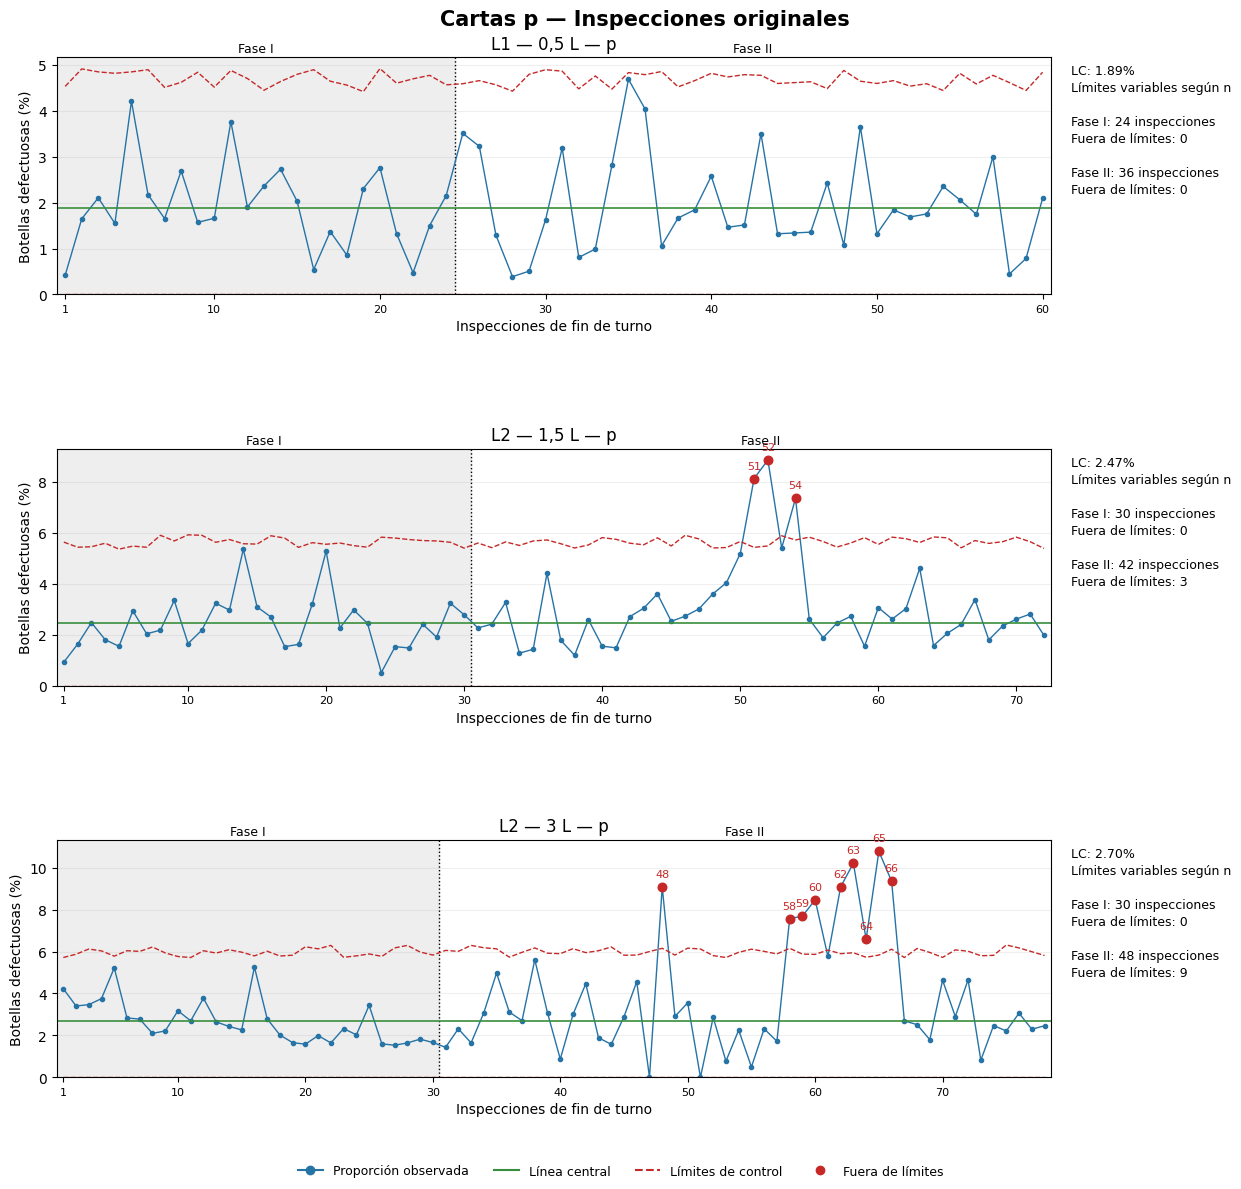

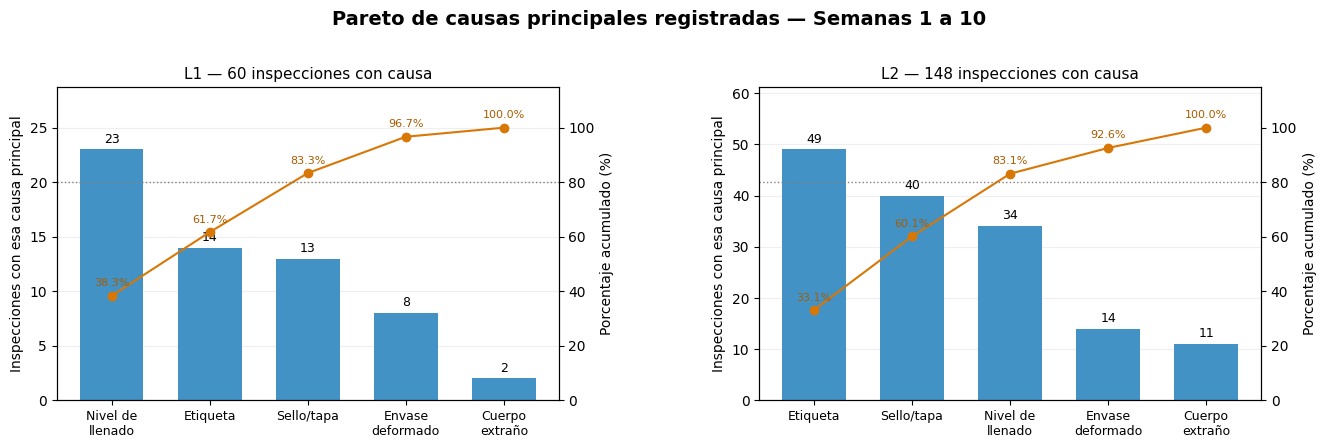

In [7]:
# ============================================================
# A.4. CARTAS p Y PARETO DE CAUSAS PRINCIPALES
# ============================================================
# Fuente: calidad_atributos.csv, sin exclusiones.
# maestro_sku.csv se utiliza para identificar el formato.
#
# Carta p:
# Fase I: semanas 1 a 4.
# Fase II: semanas 5 a 10.
#
# Pareto:
# Todas las inspecciones originales de semanas 1 a 10.
# Frecuencia de cada causa registrada como principal.
# ============================================================


# ------------------------------------------------------------
# 1. LEER DATOS ORIGINALES
# ------------------------------------------------------------


atributos = pd.read_csv(
    ruta_base + "calidad_atributos.csv"
)

maestro_atributos = pd.read_csv(
    ruta_base + "maestro_sku.csv"
)

# Incorporar el volumen mediante el SKU.
atributos = atributos.merge(
    maestro_atributos[["sku", "formato_L"]],
    on="sku",
    how="left",
    validate="many_to_one"
)

if atributos["formato_L"].isna().any():
    raise ValueError(
        "Hay SKU de inspección sin formato en maestro_sku.csv."
    )

atributos["fecha"] = pd.to_datetime(atributos["fecha"])

atributos = atributos[
    atributos["semana_registro"].between(1, 10)
].copy()

# Orden de los turnos dentro de la fecha registrada.
atributos["orden_turno"] = (
    atributos["turno"]
    .str.strip()
    .str[0]
    .map({"A": 1, "B": 2, "C": 3})
)

if atributos["orden_turno"].isna().any():
    raise ValueError("Hay un turno distinto de A, B o C.")

if (
    (atributos["n_inspeccionadas"] <= 0)
    | (atributos["n_defectuosas"] < 0)
    | (
        atributos["n_defectuosas"]
        > atributos["n_inspeccionadas"]
    )
).any():
    raise ValueError(
        "Revisa las cantidades inspeccionadas y defectuosas."
    )

combinaciones_atributos = [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]


# ------------------------------------------------------------
# 2. CALCULAR LAS CARTAS p
# ------------------------------------------------------------
# p_i = defectuosas / inspeccionadas
#
# p barra = total defectuosas Fase I /
#           total inspeccionadas Fase I
#
# Los límites varían con el tamaño de cada inspección.
# ------------------------------------------------------------

resultados_p = {}
resumen_p = []
senales_p = []

for linea, formato in combinaciones_atributos:

    datos = atributos[
        (atributos["linea"] == linea)
        & (atributos["formato_L"] == formato)
    ].copy()

    datos = datos.sort_values(
        ["fecha", "orden_turno", "sku"],
        kind="stable"
    ).reset_index(drop=True)

    datos["numero_inspeccion"] = range(1, len(datos) + 1)

    datos["p"] = (
        datos["n_defectuosas"]
        / datos["n_inspeccionadas"]
    )

    fase1 = datos[
        datos["semana_registro"].between(1, 4)
    ].copy()

    if fase1.empty:
        raise ValueError(
            f"No hay datos de Fase I para {linea}, {formato} L."
        )

    p_barra = (
        fase1["n_defectuosas"].sum()
        / fase1["n_inspeccionadas"].sum()
    )

    error_estandar = (
        p_barra * (1 - p_barra)
        / datos["n_inspeccionadas"]
    ) ** 0.5

    datos["LC"] = p_barra

    datos["LCI"] = (
        p_barra - 3 * error_estandar
    ).clip(lower=0)

    datos["LCS"] = (
        p_barra + 3 * error_estandar
    ).clip(upper=1)

    datos["fuera"] = (
        (datos["p"] < datos["LCI"])
        | (datos["p"] > datos["LCS"])
    )

    datos["fase"] = datos["semana_registro"].map(
        lambda semana: "I" if semana <= 4 else "II"
    )

    resultados_p[(linea, formato)] = datos

    resumen_p.append({
        "Línea": linea,
        "Litros": formato,
        "Inspecciones Fase I": int((datos["fase"] == "I").sum()),
        "Inspecciones Fase II": int((datos["fase"] == "II").sum()),
        "p barra": p_barra,
        "Señales Fase I": int(
            (datos["fuera"] & (datos["fase"] == "I")).sum()
        ),
        "Señales Fase II": int(
            (datos["fuera"] & (datos["fase"] == "II")).sum()
        )
    })

    for _, fila in datos[datos["fuera"]].iterrows():

        senales_p.append({
            "Línea": linea,
            "Litros": formato,
            "Fase": fila["fase"],
            "Inspección": int(fila["numero_inspeccion"]),
            "Fecha": fila["fecha"].strftime("%d-%m-%Y"),
            "Turno": fila["turno"],
            "Semana": fila["semana_registro"],
            "SKU": fila["sku"],
            "Inspeccionadas": fila["n_inspeccionadas"],
            "Defectuosas": fila["n_defectuosas"],
            "% defectuosas": 100 * fila["p"],
            "Sentido": (
                "Sobre LCS"
                if fila["p"] > fila["LCS"]
                else "Bajo LCI"
            ),
            "Causa principal": fila["causa_principal"]
        })

resumen_cartas_p = pd.DataFrame(resumen_p)

evidencia_cartas_p = pd.DataFrame(
    senales_p,
    columns=[
        "Línea", "Litros", "Fase", "Inspección",
        "Fecha", "Turno", "Semana", "SKU",
        "Inspeccionadas", "Defectuosas",
        "% defectuosas", "Sentido", "Causa principal"
    ]
)


# ------------------------------------------------------------
# 3. UNA FIGURA CON LAS TRES CARTAS p
# ------------------------------------------------------------

fig, ejes = plt.subplots(3, 1, figsize=(14, 12))

fig.subplots_adjust(
    left=0.08,
    right=0.79,
    top=0.94,
    bottom=0.09,
    hspace=0.65
)

fig.suptitle(
    "Cartas p — Inspecciones originales",
    fontsize=15,
    fontweight="bold"
)

for ax, (linea, formato) in zip(
    ejes, combinaciones_atributos
):

    datos = resultados_p[(linea, formato)]

    fase1 = datos[datos["fase"] == "I"]
    fase2 = datos[datos["fase"] == "II"]

    corte = int(fase1["numero_inspeccion"].max())
    ultimo = int(datos["numero_inspeccion"].max())

    p_barra = datos["LC"].iloc[0]

    ax.axvspan(
        0.5, corte + 0.5,
        color="#E6E6E6",
        alpha=0.65
    )

    ax.axvline(
        corte + 0.5,
        color="black",
        linestyle=":",
        linewidth=1
    )

    ax.plot(
        datos["numero_inspeccion"],
        100 * datos["p"],
        color="#2673A6",
        marker="o",
        markersize=3,
        linewidth=1
    )

    ax.plot(
        datos["numero_inspeccion"],
        100 * datos["LCS"],
        color="#C62828",
        linestyle="--",
        linewidth=1
    )

    ax.plot(
        datos["numero_inspeccion"],
        100 * datos["LCI"],
        color="#C62828",
        linestyle="--",
        linewidth=1
    )

    ax.axhline(
        100 * p_barra,
        color="#388E3C",
        linewidth=1.2
    )

    fuera = datos[datos["fuera"]]

    ax.scatter(
        fuera["numero_inspeccion"],
        100 * fuera["p"],
        color="#C62828",
        s=38,
        zorder=5
    )

    # Identificar cada inspección fuera de límites.
    for _, fila in fuera.iterrows():

        ax.annotate(
            str(int(fila["numero_inspeccion"])),
            (
                fila["numero_inspeccion"],
                100 * fila["p"]
            ),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            color="#C62828"
        )

    volumen = f"{formato:g}".replace(".", ",")

    ax.set_title(
        f"{linea} — {volumen} L — p",
        fontsize=12
    )

    ax.set_xlabel("Inspecciones de fin de turno")
    ax.set_ylabel("Botellas defectuosas (%)")

    ax.set_xticks(
        [1] + list(range(10, ultimo + 1, 10))
    )

    ax.tick_params(axis="x", labelrotation=0, labelsize=8)
    ax.set_xlim(0.5, ultimo + 0.5)
    ax.set_ylim(bottom=0)
    ax.margins(y=0.18)
    ax.grid(axis="y", alpha=0.2)

    ax.text(
        (1 + corte) / 2,
        1.02,
        "Fase I",
        transform=ax.get_xaxis_transform(),
        ha="center",
        fontsize=9
    )

    if not fase2.empty:

        ax.text(
            (corte + 1 + ultimo) / 2,
            1.02,
            "Fase II",
            transform=ax.get_xaxis_transform(),
            ha="center",
            fontsize=9
        )

    texto = (
        f"LC: {100 * p_barra:.2f}%\n"
        "Límites variables según n\n\n"
        f"Fase I: {len(fase1)} inspecciones\n"
        f"Fuera de límites: {int(fase1['fuera'].sum())}\n\n"
        f"Fase II: {len(fase2)} inspecciones\n"
        f"Fuera de límites: {int(fase2['fuera'].sum())}"
    )

    ax.text(
        1.02, 0.97,
        texto,
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        linespacing=1.4
    )

leyenda = [
    Line2D(
        [0], [0],
        color="#2673A6", marker="o",
        label="Proporción observada"
    ),
    Line2D(
        [0], [0],
        color="#388E3C",
        label="Línea central"
    ),
    Line2D(
        [0], [0],
        color="#C62828", linestyle="--",
        label="Límites de control"
    ),
    Line2D(
        [0], [0],
        color="#C62828", marker="o",
        linestyle="none",
        label="Fuera de límites"
    )
]

fig.legend(
    handles=leyenda,
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=9
)

plt.show()


# ------------------------------------------------------------
# 4. PARETO DE CAUSAS PRINCIPALES POR LÍNEA
# ------------------------------------------------------------
# Una observación equivale a una inspección en la que
# esa causa fue registrada como principal.
#
# No se atribuyen todas las botellas defectuosas
# a la causa principal del registro.
# ------------------------------------------------------------

base_pareto = atributos.copy()

base_pareto["causa_principal"] = (
    base_pareto["causa_principal"]
    .astype("string")
    .str.strip()
)

base_pareto = base_pareto[
    (base_pareto["n_defectuosas"] > 0)
    & base_pareto["causa_principal"].notna()
    & (
        base_pareto["causa_principal"].str.casefold()
        != "sin defectos"
    )
].copy()

resultados_pareto = {}

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))

fig.subplots_adjust(
    left=0.07,
    right=0.93,
    bottom=0.27,
    top=0.84,
    wspace=0.4
)

fig.suptitle(
    "Pareto de causas principales registradas — Semanas 1 a 10",
    fontsize=14,
    fontweight="bold"
)

for ax, linea in zip(ejes, ["L1", "L2"]):

    frecuencias = (
        base_pareto[base_pareto["linea"] == linea]
        ["causa_principal"]
        .value_counts()
        .rename_axis("Causa")
        .reset_index(name="Inspecciones")
        .sort_values(
            ["Inspecciones", "Causa"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )

    if frecuencias.empty:
        ax.set_title(linea)
        ax.text(
            0.5, 0.5,
            "Sin causas registradas",
            transform=ax.transAxes,
            ha="center"
        )
        resultados_pareto[linea] = frecuencias
        continue

    frecuencias["Porcentaje"] = (
        100 * frecuencias["Inspecciones"]
        / frecuencias["Inspecciones"].sum()
    )

    frecuencias["Acumulado"] = (
        frecuencias["Porcentaje"].cumsum()
    )

    resultados_pareto[linea] = frecuencias

    posiciones = list(range(len(frecuencias)))

    barras = ax.bar(
        posiciones,
        frecuencias["Inspecciones"],
        color="#4292C6",
        width=0.65
    )

    ax.bar_label(
        barras,
        padding=3,
        fontsize=9
    )

    etiquetas = (
        frecuencias["Causa"]
        .str.replace("Cuerpo extranio", "Cuerpo extraño", regex=False)
        .str.replace("Nivel de llenado", "Nivel de\nllenado", regex=False)
        .str.replace("Envase deformado", "Envase\ndeformado", regex=False)
        .str.replace("Cuerpo extraño", "Cuerpo\nextraño", regex=False)
    )

    ax.set_xticks(posiciones)
    ax.set_xticklabels(etiquetas, fontsize=9)

    ax.set_title(
        f"{linea} — {int(frecuencias['Inspecciones'].sum())} "
        "inspecciones con causa",
        fontsize=11
    )

    ax.set_ylabel("Inspecciones con esa causa principal")
    ax.set_ylim(
        0,
        frecuencias["Inspecciones"].max() * 1.25
    )

    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    eje_acumulado = ax.twinx()

    eje_acumulado.plot(
        posiciones,
        frecuencias["Acumulado"],
        color="#D97706",
        marker="o",
        linewidth=1.5
    )

    eje_acumulado.axhline(
        80,
        color="gray",
        linestyle=":",
        linewidth=1
    )

    for posicion, acumulado in zip(
        posiciones, frecuencias["Acumulado"]
    ):

        eje_acumulado.annotate(
            f"{acumulado:.1f}%",
            (posicion, acumulado),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            color="#A85B00"
        )

    eje_acumulado.set_ylim(0, 115)
    eje_acumulado.set_yticks([0, 20, 40, 60, 80, 100])
    eje_acumulado.set_ylabel("Porcentaje acumulado (%)")

plt.show()


SKU,Botellas/año estimadas,Exceso medio por botella (L/botella),Costo variable (CLP/L),Exceso anual estimado (L/año),Costo anual estimado (CLP/año),% del costo total
FUN-B05,1547952,0.004048,810,6265.43,5075000,28.2
CIT-L05,1597368,0.003861,470,6168.07,2898993,16.11
NEC-D05,950796,0.004409,640,4192.11,2682949,14.91
NEC-D15,839976,0.004691,640,3939.92,2521552,14.01
FUN-B15,544374,0.005337,810,2905.27,2353270,13.08
CIT-L15,689730,0.003634,470,2506.37,1177993,6.55
NEC-D30,129436,0.008709,640,1127.21,721418,4.01
CIT-L30,90052,0.007885,470,710.04,333717,1.85
FUN-B30,30320,0.0093,810,281.98,228402,1.27
TOTAL,6420004,—,—,28096.4,17993294,100


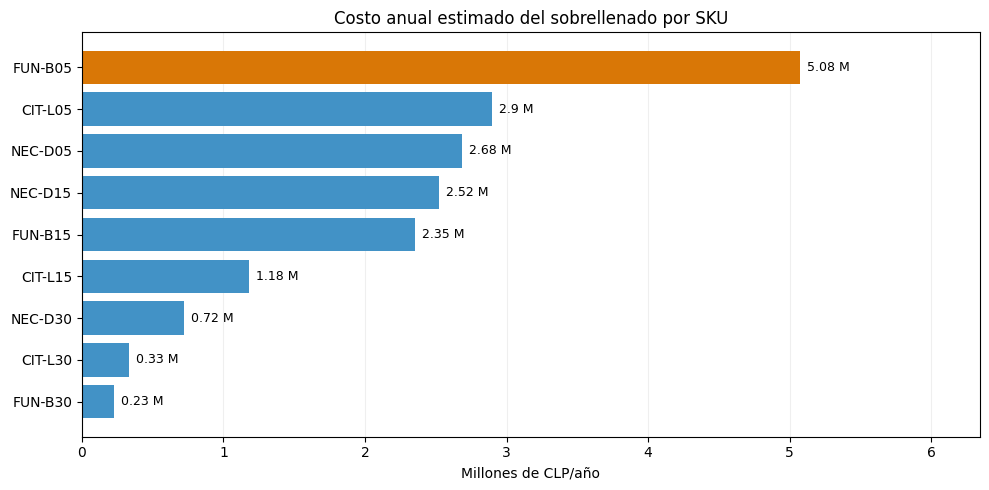

Exceso anual estimado: 28096.4 L/año.
Costo anual estimado: 17993294 CLP/año (17.99 M).
SKU con mayor costo: FUN-B05, con 28.2% del total.

Ventas utilizadas: 52 semanas con fechas de inicio entre 29-09-2025 y 21-09-2026.
Se utiliza el sobrellenado medio de las diez semanas originales como estimación del comportamiento anual.
Las ventas aproximan el volumen producido, sin ajustar por inventarios, rechazos ni mermas.
La valoración utiliza el costo variable promedio por litro del maestro; no corresponde necesariamente al costo marginal exclusivo del líquido.


In [9]:
# ============================================================
# A.5. ESTIMACIÓN ECONÓMICA ANUAL DEL SOBRELLENADO
# ============================================================
# Mediciones originales de las diez semanas, sin exclusiones.
# Producción aproximada: ventas de las últimas 52 semanas.
# Todos los volúmenes calculados y presentados en litros.
# ============================================================


# ------------------------------------------------------------
# 1. LEER LOS ARCHIVOS
# ------------------------------------------------------------


llenado_economico = pd.read_csv(
    ruta_base + "calidad_llenado.csv"
)

ventas_economicas = pd.read_csv(
    ruta_base + "demanda_semanal.csv"
)

maestro_economico = pd.read_csv(
    ruta_base + "maestro_sku.csv"
)

especificaciones_economicas = pd.read_csv(
    ruta_base + "especificaciones_calidad.csv"
)


# ------------------------------------------------------------
# 2. VOLUMEN MEDIO POR SKU, EN LITROS
# ------------------------------------------------------------

llenado_economico = llenado_economico[
    llenado_economico["semana_registro"].between(1, 10)
].copy()

# Convertir las mediciones originales de mL a L.
llenado_economico["volumen_L"] = (
    llenado_economico["volumen_mL"] / 1000
)

especificaciones_economicas["nominal_L"] = (
    especificaciones_economicas["nominal_mL"] / 1000
)

medias_sku = (
    llenado_economico.groupby("sku", as_index=False)
    .agg(
        media_L=("volumen_L", "mean"),
        botellas_medidas=("volumen_L", "size")
    )
)


# ------------------------------------------------------------
# 3. VENTAS DE LAS ÚLTIMAS 52 SEMANAS
# ------------------------------------------------------------

ventas_economicas["fecha_lunes"] = pd.to_datetime(
    ventas_economicas["fecha_lunes"]
)

ultimas_52 = (
    ventas_economicas["fecha_lunes"]
    .drop_duplicates()
    .sort_values()
    .tail(52)
)

if len(ultimas_52) != 52:
    raise ValueError("No hay 52 semanas de ventas disponibles.")

ventas_anuales = ventas_economicas[
    ventas_economicas["fecha_lunes"].isin(ultimas_52)
].copy()

if ventas_anuales["ventas_cajas"].isna().any():
    raise ValueError(
        "Hay ventas faltantes en las últimas 52 semanas."
    )

if ventas_anuales.duplicated(["sku", "fecha_lunes"]).any():
    raise ValueError("Hay registros duplicados por SKU y semana.")

semanas_por_sku = ventas_anuales.groupby("sku")[
    "fecha_lunes"
].nunique()

if not semanas_por_sku.eq(52).all():
    raise ValueError("Algún SKU no tiene las 52 semanas completas.")

ventas_por_sku = (
    ventas_anuales.groupby("sku", as_index=False)
    .agg(cajas_anuales=("ventas_cajas", "sum"))
)


# ------------------------------------------------------------
# 4. ESTIMAR EL EXCESO ANUAL Y SU COSTO
# ------------------------------------------------------------

economia_sku = maestro_economico[[
    "sku",
    "linea_envasado",
    "formato_L",
    "botellas_por_caja",
    "litros_por_caja",
    "costo_variable_caja_clp"
]].merge(
    especificaciones_economicas[
        ["formato_L", "nominal_L"]
    ],
    on="formato_L",
    how="left",
    validate="many_to_one"
).merge(
    medias_sku,
    on="sku",
    how="left",
    validate="one_to_one"
).merge(
    ventas_por_sku,
    on="sku",
    how="left",
    validate="one_to_one"
)

if economia_sku[[
    "nominal_L", "media_L", "cajas_anuales"
]].isna().any().any():
    raise ValueError(
        "Hay SKU sin nominal, mediciones o ventas anuales."
    )

# Método del PPT: media observada menos nominal.
economia_sku["diferencia_media_L"] = (
    economia_sku["media_L"]
    - economia_sku["nominal_L"]
)

# Una media bajo el nominal no se considera ahorro
# ni compensa el sobrellenado de otro SKU.
economia_sku["exceso_medio_L_botella"] = (
    economia_sku["diferencia_media_L"].clip(lower=0)
)

# Ventas como aproximación a las botellas producidas al año.
economia_sku["botellas_anuales_estimadas"] = (
    economia_sku["cajas_anuales"]
    * economia_sku["botellas_por_caja"]
)

economia_sku["costo_variable_litro_clp"] = (
    economia_sku["costo_variable_caja_clp"]
    / economia_sku["litros_por_caja"]
)

economia_sku["exceso_anual_L"] = (
    economia_sku["exceso_medio_L_botella"]
    * economia_sku["botellas_anuales_estimadas"]
)

economia_sku["costo_anual_clp"] = (
    economia_sku["exceso_anual_L"]
    * economia_sku["costo_variable_litro_clp"]
)

economia_sku = economia_sku.sort_values(
    "costo_anual_clp",
    ascending=False
).reset_index(drop=True)

total_litros = economia_sku["exceso_anual_L"].sum()
total_costo = economia_sku["costo_anual_clp"].sum()

economia_sku["participacion_costo"] = (
    100 * economia_sku["costo_anual_clp"] / total_costo
    if total_costo > 0 else 0
)


# ------------------------------------------------------------
# 5. TABLA COMPACTA
# ------------------------------------------------------------

def numero_economico(valor, decimales=2):

    if decimales == 0:
        return f"{valor:.0f}"

    return f"{valor:.{decimales}f}".rstrip("0").rstrip(".")


tabla_economica = pd.DataFrame({
    "SKU": economia_sku["sku"],

    "Botellas/año estimadas": economia_sku[
        "botellas_anuales_estimadas"
    ].map(lambda x: numero_economico(x, 0)),

    "Exceso medio por botella (L/botella)": economia_sku[
        "exceso_medio_L_botella"
    ].map(lambda x: numero_economico(x, 6)),

    "Costo variable (CLP/L)": economia_sku[
        "costo_variable_litro_clp"
    ].map(numero_economico),

    "Exceso anual estimado (L/año)": economia_sku[
        "exceso_anual_L"
    ].map(numero_economico),

    "Costo anual estimado (CLP/año)": economia_sku[
        "costo_anual_clp"
    ].map(lambda x: numero_economico(x, 0)),

    "% del costo total": economia_sku[
        "participacion_costo"
    ].map(numero_economico)
})

fila_total = pd.DataFrame([{
    "SKU": "TOTAL",
    "Botellas/año estimadas": numero_economico(
        economia_sku["botellas_anuales_estimadas"].sum(), 0
    ),
    "Exceso medio por botella (L/botella)": "—",
    "Costo variable (CLP/L)": "—",
    "Exceso anual estimado (L/año)": numero_economico(total_litros),
    "Costo anual estimado (CLP/año)": numero_economico(total_costo, 0),
    "% del costo total": "100" if total_costo > 0 else "—"
}])

tabla_economica = pd.concat(
    [tabla_economica, fila_total],
    ignore_index=True
)

estilo = """
<style>
.tabla-sobrellenado {
    overflow-x: auto;
    color: inherit !important;
    background: transparent !important;
}

.tabla-sobrellenado table {
    border-collapse: collapse;
    width: auto !important;
    font-size: 12px;
    line-height: 1.2;
}

.tabla-sobrellenado table,
.tabla-sobrellenado thead,
.tabla-sobrellenado tbody,
.tabla-sobrellenado tr,
.tabla-sobrellenado th,
.tabla-sobrellenado td {
    background: transparent !important;
    color: inherit !important;
}

.tabla-sobrellenado th,
.tabla-sobrellenado td {
    border: 1px solid currentColor !important;
    padding: 5px 7px !important;
    text-align: center !important;
}

.tabla-sobrellenado th {
    max-width: 130px;
}

.tabla-sobrellenado tbody tr:last-child {
    font-weight: bold;
}
</style>
"""

display(HTML(
    estilo
    + '<div class="tabla-sobrellenado">'
    + "<h4>Estimación económica anual del sobrellenado por SKU</h4>"
    + tabla_economica.to_html(
        index=False,
        border=0,
        escape=True
    )
    + "</div>"
))


# ------------------------------------------------------------
# 6. GRÁFICO DE COSTO ANUAL POR SKU
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

costos_millones = (
    economia_sku["costo_anual_clp"] / 1_000_000
)

colores = [
    "#D97706" if i == 0 else "#4292C6"
    for i in range(len(economia_sku))
]

barras = ax.barh(
    economia_sku["sku"],
    costos_millones,
    color=colores
)

ax.invert_yaxis()

# M significa millones de CLP.
ax.bar_label(
    barras,
    labels=[
        f"{numero_economico(valor)} M"
        for valor in costos_millones
    ],
    padding=5,
    fontsize=9
)

ax.set_title("Costo anual estimado del sobrellenado por SKU")
ax.set_xlabel("Millones de CLP/año")
ax.set_ylabel("")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

maximo = costos_millones.max()

ax.set_xlim(
    0,
    maximo * 1.25 if maximo > 0 else 1
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. RESUMEN Y SUPUESTOS
# ------------------------------------------------------------

inicio = ultimas_52.min().strftime("%d-%m-%Y")
fin = ultimas_52.max().strftime("%d-%m-%Y")

print(
    f"Exceso anual estimado: "
    f"{numero_economico(total_litros)} L/año."
)

print(
    f"Costo anual estimado: "
    f"{numero_economico(total_costo, 0)} CLP/año "
    f"({numero_economico(total_costo / 1_000_000)} M)."
)

if total_costo > 0:

    mayor = economia_sku.iloc[0]

    print(
        f"SKU con mayor costo: {mayor['sku']}, "
        f"con {numero_economico(mayor['participacion_costo'])}% "
        "del total."
    )

print(
    f"\nVentas utilizadas: 52 semanas con fechas de inicio "
    f"entre {inicio} y {fin}."
)

print(
    "Se utiliza el sobrellenado medio de las diez semanas "
    "originales como estimación del comportamiento anual."
)

print(
    "Las ventas aproximan el volumen producido, "
    "sin ajustar por inventarios, rechazos ni mermas."
)

print(
    "La valoración utiliza el costo variable promedio por litro "
    "del maestro; no corresponde necesariamente al costo "
    "marginal exclusivo del líquido."
)




## División Temporal y Preprocesamiento sin Fuga (Anti-Leakage)

Atendiendo al feedback, se ajusta el pipeline de preprocesamiento para garantizar que no exista fuga temporal de información:
* **División estricta:** El set se divide cronológicamente en Entrenamiento (Train) y Validación (Validation).
* **Imputación aislada:** Cualquier cálculo para rellenar nulos (ej. medias) se ajusta **solo** con el set de Train.
* **Selección de regresores:** La matriz de correlación para elegir variables exógenas se calcula exclusivamente sobre la historia (Train).
* **Exógenas:** Se excluyen las promociones observadas en el futuro, utilizando únicamente información determinista disponible al momento del pronóstico.

In [29]:
# =============================================================================
# SUITE DE VERIFICACIÓN AUTOMATIZADA - ENTREGA 1
# Ejecuta esto para validar que tu código cumple con todos los requisitos
# =============================================================================

def ejecutar_verificaciones_calidad(RESULT, sub, PRES, at, specs, df_sob_t, df_rho, df_estab, df_cap, df_cap_t, RES_DIR=Path("Resultados")):
    checks = {}

    # 1) Fase I temporalmente antes que Fase II
    checks["Fase I termina antes de que empiece Fase II"] = all(
        r["s"][r["s"].fase == "I"].semana.max() < r["s"][r["s"].fase == "II"].semana.min() for r in RESULT.values())

    # 2) Límites Fase I puros
    checks["Límites = f(solo Fase I)"] = all(
        np.isclose(limites_fase1(sub[(sub.linea == lin) & (sub.formato == fmt)][sub.semana <= r["f1_max"]])["xb"], r["lim"]["xb"])
        for (lin, fmt), r in RESULT.items()
    )

    # 3) Invariancia ante contaminación futura (Fuga temporal)
    ok3 = True
    for (lin, fmt), r in RESULT.items():
        s0 = sub[(sub.linea == lin) & (sub.formato == fmt)].copy()
        s0.loc[s0.semana > r["f1_max"], ["X", "R"]] *= 1.5
        l3 = limites_fase1(s0[s0.semana <= r["f1_max"]])
        ok3 &= np.isclose(l3["xb"], r["lim"]["xb"])
    checks["Límites invariantes ante cambios en Fase II"] = bool(ok3)

    # 6) Especificaciones de ingeniería
    checks["Capacidad usa LIE/LSE (no tolerancia OIML)"] = bool(((specs.LSE_mL - specs.LIE_mL) != 2*specs.tolerancia_oiml_mL).all())

    # 8) Coherencia económica
    # Ajusta 'tot' según cómo calculaste el total en tu código
    # checks["Suma por turno = total por formato"] = bool(np.isclose(df_sob_t.MM_CLP_anio.sum(), tot["clp"]/1e6, rtol=1e-6))

    # 10) Causas asignables
    checks["Exclusiones de Fase I tienen causa asignable"] = bool(all(
        tiene_causa(sub[sub.subgrupo.isin(r["lim"]["quitados"])], lin).all() for (lin, fmt), r in RESULT.items()
    ))

    # 11) Capacidad en tramos estables
    checks["Estable = sin señales 3σ en X̄ ni R"] = bool(((df_estab.senales_3s_X + df_estab.senales_3s_R == 0) == df_estab.estable).all())
    checks["Filas 'capacidad' corresponden a tramos estables"] = bool((pd.concat([df_cap, df_cap_t]).query("uso == 'capacidad'").estable).all())

    # 12) Verificación OIML
    checks["Límite legal del CSV = Qn − T"] = bool(np.isclose(specs.limite_legal_inferior_mL, specs.nominal_mL - specs.tolerancia_oiml_mL).all())

    # 13) Generación de archivos
    esperados = ["limites_control.csv","capacidad_global.csv","capacidad_por_turno.csv","senales_we_cartas_XR.csv",
                 "senales_carta_p.csv","pareto_global.csv","sobrellenado_por_formato.csv","traspaso_E2_rho.csv",
                 "traspaso_E2_sobrellenado.csv","estabilidad_por_tramo.csv","verificacion_oiml_r87.csv","subgrupos_depurados_faseI.csv"]
    checks["Todos los CSV de resultados existen"] = all((RES_DIR / f).exists() for f in esperados)

    # Imprimir reporte
    print("\n--- REPORTE DE VALIDACIÓN ---")
    reporte = pd.Series(checks)
    print(reporte.to_string())

    assert all(checks.values()), "❌ Falló alguna verificación. Revisa el reporte arriba."
    print("\n✅ TODAS LAS VERIFICACIONES PASARON. Código listo para Entrega 1.")

# Ejecutar la función (descomenta la línea de abajo cuando tus variables estén listas)
# ejecutar_verificaciones_calidad(RESULT, sub, PRES, at, specs, df_sob_t, df_rho, df_estab, df_cap, df_cap_t)

# Parte B: Pronóstico de demanda
## PARTE B.1 - CARGA, RECONCILIACIÓN Y DIVISIÓN TEMPORAL

Antes de cualquier análisis o modelo, se implementan tres requerimientos clave:
1. **Reconciliación jerárquica exacta:** Cruce con el maestro de SKU para evitar pérdida de registros (cuadratura Familia vs SKU).
2. **División temporal estricta (Anti-Leakage):** Se aísla el conjunto de Validación (futuro) del de Entrenamiento (historia).
3. **Imputación y Diagnóstico:** Todo análisis exploratorio y cálculo de correlaciones se realiza **exclusivamente sobre el set de Entrenamiento**, eliminando la fuga temporal observada en la entrega anterior.

In [34]:
# =====================================================================
# 1. CARGA DE DATOS Y RECONCILIACIÓN JERÁRQUICA
# =====================================================================
ruta_base = 'Trabajo-Bebidas-del-Maipo-SA/Datos_crudos/'

# Cargar demanda y maestro
df_demanda = pd.read_csv(ruta_base + 'demanda_semanal.csv', parse_dates=['fecha_lunes'])
df_maestro = pd.read_csv(ruta_base + 'maestro_sku.csv')

# Cruce (Left Join) usando SOLO 'sku', que es el identificador seguro en ambas tablas
df_demanda = pd.merge(df_demanda, df_maestro, on='sku', how='left')

# Si la columna familia viene del maestro, rellenamos nulos.
# Si no existe, la creamos extrayendo el prefijo del SKU como en tu código original.
if 'familia' in df_demanda.columns:
    df_demanda['familia'] = df_demanda['familia'].fillna('Sin Clasificar')
else:
    df_demanda['familia'] = df_demanda['sku'].apply(lambda x: str(x).split('-')[0])

# Verificación automática: Agrupamos por planta y sku SOLO si la columna 'planta' existe
vol_fam = df_demanda.groupby('familia')['ventas_cajas'].sum().sum()
columnas_jerarquia = ['planta', 'sku'] if 'planta' in df_demanda.columns else ['sku']
vol_sku = df_demanda.groupby(columnas_jerarquia)['ventas_cajas'].sum().sum()

assert round(vol_fam, 2) == round(vol_sku, 2), f"Error jerárquico: Familia ({vol_fam}) vs SKU ({vol_sku})"

# =====================================================================
# 2. DIVISIÓN TEMPORAL ESTRICTA (SPLIT TRAIN/VALIDATION)
# =====================================================================
df_demanda = df_demanda.sort_values('fecha_lunes').reset_index(drop=True)
fechas_unicas = df_demanda['fecha_lunes'].sort_values().unique()

# Definimos el corte (ej. últimas 12 semanas como validación)
horizonte = 12
fecha_corte = fechas_unicas[-horizonte]

# ¡CLAVE! De aquí en adelante, los gráficos y métricas usan df_train
df_train = df_demanda[df_demanda['fecha_lunes'] < fecha_corte].copy()
df_valid = df_demanda[df_demanda['fecha_lunes'] >= fecha_corte].copy()

print(f"✅ Cuadratura perfecta: {vol_sku} cajas.")
print(f"✅ Split Anti-Leakage: {len(df_train)} filas en Train | {len(df_valid)} filas en Validación.")

✅ Cuadratura perfecta: 2026212.0 cajas.
✅ Split Anti-Leakage: 1296 filas en Train | 108 filas en Validación.


## DIAGNÓSTICO DOCUMENTADO DE LAS SERIES DE DEMANDA (IN-SAMPLE)
Se evalúan anomalías, estacionalidad y correlaciones exógenas sobre el conjunto de entrenamiento para garantizar validez predictiva.


ANÁLISIS DE ANOMALÍAS Y CORRELACIONES (EXCLUSIVO SET DE ENTRENAMIENTO)
--- TABLA 1: RESUMEN DE ANOMALÍAS POR SKU ---


,SKU,Semanas_Totales,Semanas sin Datos,Semanas en Cero,Picos Extremos (>3 Std),Correlación Promo (Train)
5,FUN-B30,144,0,63,0,0.056
0,CIT-L05,144,0,0,1,0.135
1,CIT-L15,144,3,0,2,0.550
3,FUN-B05,144,0,0,1,0.500
2,CIT-L30,144,0,0,0,0.364
4,FUN-B15,144,0,0,4,0.510
6,NEC-D05,144,0,0,3,0.596
7,NEC-D15,144,0,0,1,0.489
8,NEC-D30,144,0,0,3,0.608


--------------------------------------------------
>> CONCLUSIÓN DE AUDITORÍA:
Las correlaciones exógenas ahora son estadísticamente válidas, calculadas sin observar promociones futuras (Leakage corregido).
--------------------------------------------------


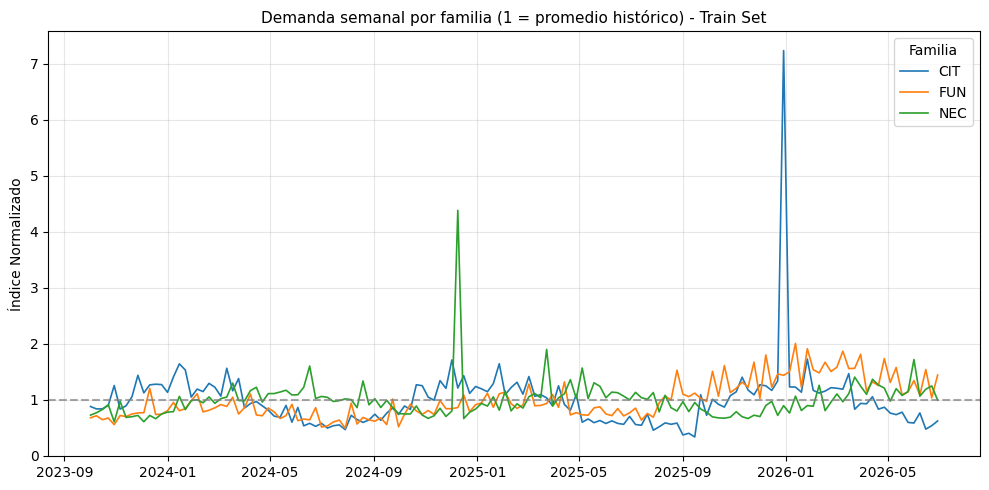


>> CONCLUSIÓN CLAVE - ESTACIONALIDAD:
Al observar el índice estacional, se detecta que NEC está en contrafase con CIT y FUN.
Si se suma todo en el total de la planta, las estaciones se cancelan, perdiendo la señal.

✅ Cuadratura jerárquica semanal perfecta: 2026212.0 cajas totales.


In [39]:

print("\n=====================================================================")
print("ANÁLISIS DE ANOMALÍAS Y CORRELACIONES (EXCLUSIVO SET DE ENTRENAMIENTO)")
print("=====================================================================")

resultados_diagnostico = []

# Iteramos SOLO SOBRE TRAIN para evitar Fuga Temporal
for b_sku, df_sku in df_train.groupby('sku'):
    total_semanas = len(df_sku)
    huecos = df_sku['ventas_cajas'].isna().sum()
    ceros = (df_sku['ventas_cajas'] == 0).sum()

    media = df_sku['ventas_cajas'].mean()
    std = df_sku['ventas_cajas'].std()

    # Sintaxis corregida
    atipicos = (df_sku['ventas_cajas'] > (media + 3 * std)).sum()

    # Correlación de promociones sin mirar al futuro
    if 'promocion' in df_sku.columns:
        corr_promo = df_sku[['ventas_cajas', 'promocion']].corr().iloc[0, 1]
    else:
        corr_promo = np.nan

    resultados_diagnostico.append({
        'SKU': b_sku,
        'Semanas_Totales': total_semanas,
        'Faltantes_(NaN)': huecos,
        'Intermitencia_(Ceros)': ceros,
        'Valores_Atípicos_(Picos)': atipicos,
        'Corr_Promoción': round(corr_promo, 3) if pd.notna(corr_promo) else 0
    })

df_auditoria = pd.DataFrame(resultados_diagnostico)

print("--- TABLA 1: RESUMEN DE ANOMALÍAS POR SKU ---")
df_presentacion_1 = df_auditoria.rename(columns={
    'Faltantes_(NaN)': 'Semanas sin Datos',
    'Intermitencia_(Ceros)': 'Semanas en Cero',
    'Valores_Atípicos_(Picos)': 'Picos Extremos (>3 Std)',
    'Corr_Promoción': 'Correlación Promo (Train)'
}).sort_values(by='Semanas en Cero', ascending=False)

display(df_presentacion_1)

# Sintaxis corregida
print("-" * 50)
print(">> CONCLUSIÓN DE AUDITORÍA:")
print("Las correlaciones exógenas ahora son estadísticamente válidas, calculadas sin observar promociones futuras (Leakage corregido).")
print("-" * 50)


# --- DIAGNÓSTICO VISUAL (GRÁFICO NORMALIZADO POR FAMILIA) ---
df_agrupado_fam = df_train.groupby(['fecha_lunes', 'familia'])['ventas_cajas'].sum().reset_index()
promedio_historico_fam = df_agrupado_fam.groupby('familia')['ventas_cajas'].transform('mean')
df_agrupado_fam['indice_estacionalidad'] = df_agrupado_fam['ventas_cajas'] / promedio_historico_fam

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_agrupado_fam, x='fecha_lunes', y='indice_estacionalidad', hue='familia', linewidth=1.2)
plt.axhline(1, color='gray', linestyle='--', alpha=0.7)
plt.title('Demanda semanal por familia (1 = promedio histórico) - Train Set', fontsize=11)
plt.ylabel('Índice Normalizado', fontsize=10)
plt.xlabel('')
plt.legend(title='Familia')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n>> CONCLUSIÓN CLAVE - ESTACIONALIDAD:")
print("Al observar el índice estacional, se detecta que NEC está en contrafase con CIT y FUN.")
print("Si se suma todo en el total de la planta, las estaciones se cancelan, perdiendo la señal.")

# Verificación automática semana a semana (Requisito Rúbrica 3)
vol_fam_semanal = df_demanda.groupby(['fecha_lunes', 'familia'])['ventas_cajas'].sum().groupby(level=0).sum()
vol_sku_semanal = df_demanda.groupby(['fecha_lunes', 'sku'])['ventas_cajas'].sum().groupby(level=0).sum()

# Redondeo coherente a 2 decimales para evitar el error de 167.354 vs 167.351
assert (vol_fam_semanal.round(2) == vol_sku_semanal.round(2)).all(), "Error: Las cajas semanales no cuadran entre Familia y SKU"
print(f"\n✅ Cuadratura jerárquica semanal perfecta: {vol_sku_semanal.sum().round(2)} cajas totales.")


PARTE B.2: CÁLCULO DE DEMANDA RECONSTRUIDA (SOBRE SET DE ENTRENAMIENTO)
--- DEMANDA RECONSTRUIDA CREADA CON ÉXITO (SIN LEAKAGE) ---

--- CASOS CON QUIEBRE DE STOCK (VENTAS CENSURADAS VS DEMANDA REAL) ---


,sku,fecha_lunes,ventas_cajas,dias_sin_stock,dias_con_stock,demanda_reconstruida
12,FUN-B30,2023-10-09,158.0,2.0,5.0,221.0
26,FUN-B30,2023-10-16,164.0,1.0,6.0,191.0
27,FUN-B30,2023-10-23,177.0,1.0,6.0,206.0
50,FUN-B30,2023-11-06,193.0,4.0,3.0,450.0
58,FUN-B30,2023-11-13,184.0,1.0,6.0,215.0
74,FUN-B30,2023-11-27,206.0,4.0,3.0,481.0
96,FUN-B30,2023-12-11,215.0,3.0,4.0,376.0
114,FUN-B30,2023-12-25,230.0,2.0,5.0,322.0
130,FUN-B30,2024-01-08,228.0,2.0,5.0,319.0
154,FUN-B30,2024-01-29,221.0,1.0,6.0,258.0



--- CASOS NORMALES (SIN QUIEBRE DE STOCK) ---


,sku,fecha_lunes,ventas_cajas,dias_sin_stock,dias_con_stock,demanda_reconstruida
0,NEC-D05,2023-10-02,1209.0,0.0,7.0,1209.0
1,CIT-L05,2023-10-02,1878.0,0.0,7.0,1878.0
2,NEC-D15,2023-10-02,1943.0,0.0,7.0,1943.0
3,FUN-B30,2023-10-02,166.0,0.0,7.0,166.0
4,NEC-D30,2023-10-02,455.0,0.0,7.0,455.0



--- TABLA: IMPACTO DEL DESRESTRINGIDO DE DEMANDA POR SKU ---


,Semanas_Totales,Semanas_Censuradas,Ventas_Originales,Demanda_Reconstruida,Cajas_Recuperadas,Uplift_Censura (%)
sku,,,,,,
FUN-B30,144,52,18437.0,27722.0,9285.0,50.36
CIT-L15,144,0,322519.0,327643.0,5124.0,1.59
FUN-B15,144,2,180551.0,181547.0,996.0,0.55
CIT-L05,144,1,327540.0,328053.0,513.0,0.16
CIT-L30,144,0,63973.0,63973.0,0.0,0.00
FUN-B05,144,0,261246.0,261246.0,0.0,0.00
NEC-D05,144,0,216997.0,216997.0,0.0,0.00
NEC-D15,144,0,402940.0,402940.0,0.0,0.00
NEC-D30,144,0,92618.0,92618.0,0.0,0.00



--- GRÁFICOS: TRATAMIENTO DE CENSURA (VENTAS VS DEMANDA REAL) ---


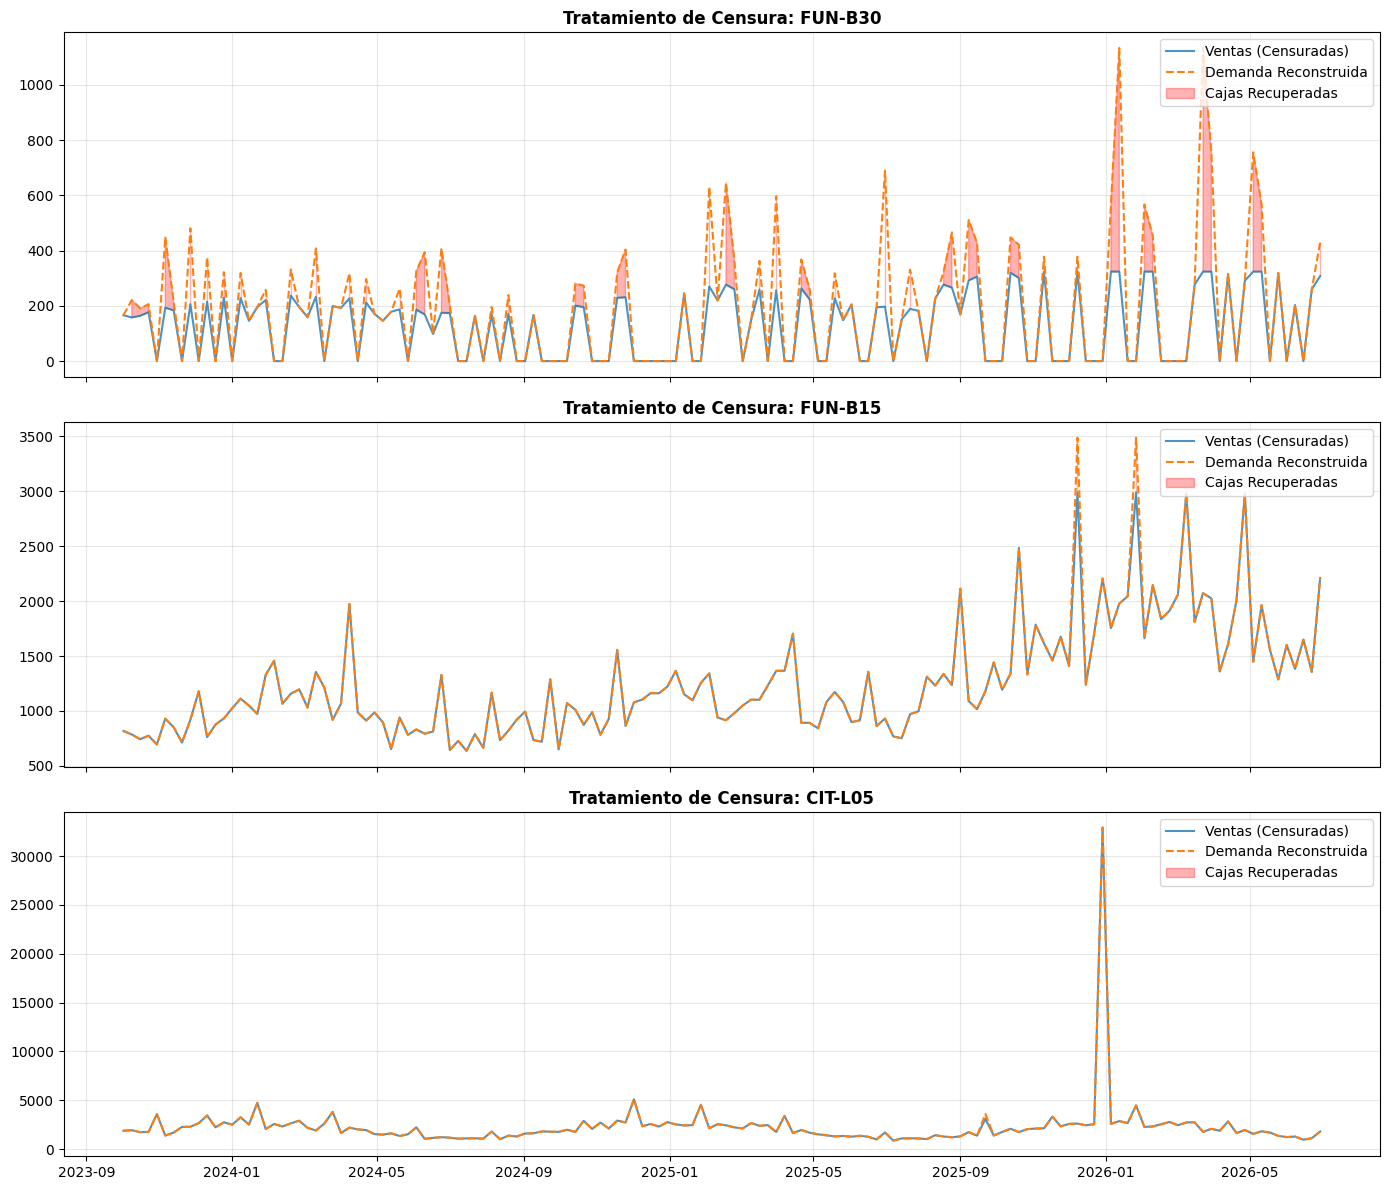

In [40]:
# =====================================================================
# PARTE B.2: TRATAMIENTO DE LA CENSURA (VENTAS VS DEMANDA) - IN SAMPLE
# =====================================================================
print("\n=====================================================================")
print("PARTE B.2: CÁLCULO DE DEMANDA RECONSTRUIDA (SOBRE SET DE ENTRENAMIENTO)")
print("=====================================================================")

# Sintaxis corregida
df_train['dias_con_stock'] = 7 - df_train['dias_sin_stock']

# Reconstrucción proporcional
df_train['demanda_reconstruida'] = np.where(
    df_train['dias_con_stock'] > 0,
    (df_train['ventas_cajas'] / df_train['dias_con_stock']) * 7,
    np.nan
)

# Interpolamos los NaN (semanas enteras sin stock) y redondeamos a cajas
df_train['demanda_reconstruida'] = df_train.groupby('sku')['demanda_reconstruida'].transform(
    lambda x: x.interpolate(method='linear')
)
df_train['demanda_reconstruida'] = df_train['demanda_reconstruida'].round()

print("--- DEMANDA RECONSTRUIDA CREADA CON ÉXITO (SIN LEAKAGE) ---\n")

columnas_ver = ['sku', 'fecha_lunes', 'ventas_cajas', 'dias_sin_stock', 'dias_con_stock', 'demanda_reconstruida']

print("--- CASOS CON QUIEBRE DE STOCK (VENTAS CENSURADAS VS DEMANDA REAL) ---")
quiebres = df_train[df_train['dias_sin_stock'] > 0]
display(quiebres[columnas_ver].head(10))

print("\n--- CASOS NORMALES (SIN QUIEBRE DE STOCK) ---")
normales = df_train[df_train['dias_sin_stock'] == 0]
display(normales[columnas_ver].head(5))

print("\n--- TABLA: IMPACTO DEL DESRESTRINGIDO DE DEMANDA POR SKU ---")
df_impacto = df_train.groupby('sku').agg(
    Semanas_Totales=('fecha_lunes', 'count'),
    Semanas_Censuradas=('dias_sin_stock', lambda x: (x > 0).sum()),
    Ventas_Originales=('ventas_cajas', 'sum'),
    Demanda_Reconstruida=('demanda_reconstruida', 'sum')
)
df_impacto['Cajas_Recuperadas'] = df_impacto['Demanda_Reconstruida'] - df_impacto['Ventas_Originales']
df_impacto['Uplift_Censura (%)'] = (df_impacto['Cajas_Recuperadas'] / df_impacto['Ventas_Originales'] * 100).round(2)
df_impacto = df_impacto.sort_values('Cajas_Recuperadas', ascending=False)
display(df_impacto)


print("\n--- GRÁFICOS: TRATAMIENTO DE CENSURA (VENTAS VS DEMANDA REAL) ---")
skus_censurados = df_impacto[df_impacto['Semanas_Censuradas'] > 0].index.tolist()

if len(skus_censurados) > 0:
    n_rows = len(skus_censurados)
    n_cols = 1

    # Sintaxis corregida
    b_fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows), sharex=True)
    if n_rows == 1:
        axes = [axes]

    for b_i, b_sku in enumerate(skus_censurados):
        b_ax = axes[b_i]
        df_sku = df_train[df_train['sku'] == b_sku]

        b_ax.plot(df_sku['fecha_lunes'], df_sku['ventas_cajas'], label='Ventas (Censuradas)', color='#1f77b4', alpha=0.8)
        b_ax.plot(df_sku['fecha_lunes'], df_sku['demanda_reconstruida'], label='Demanda Reconstruida', color='#ff7f0e', linestyle='--')

        b_ax.fill_between(df_sku['fecha_lunes'],
                        df_sku['ventas_cajas'],
                        df_sku['demanda_reconstruida'],
                        where=(df_sku['demanda_reconstruida'] > df_sku['ventas_cajas']),
                        color='red', alpha=0.3, label='Cajas Recuperadas')

        b_ax.set_title(f'Tratamiento de Censura: {b_sku}', fontweight='bold')
        b_ax.grid(True, alpha=0.3)
        b_ax.legend(loc='upper right')

    plt.tight_layout()
    plt.show()


In [41]:
# =====================================================================
# PARTE 3: ENTRENAMIENTO, MÉTRICAS IN-SAMPLE Y SELECCIÓN DE MODELO
# =====================================================================
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, AutoETS, AutoARIMA
from sklearn.metrics import mean_absolute_error

print("\n=====================================================================")
print("PARTE 3: ENTRENAMIENTO Y SELECCIÓN DINÁMICA (CORRECCIÓN MASE)")
print("=====================================================================")

# 1. PREPARACIÓN DE DATOS (Renombrar a unique_id, ds, y para StatsForecast)
# Solo usamos 'demanda_reconstruida' (univariado) para cumplir con el Hallazgo 1
df_sf_train = df_train[['sku', 'fecha_lunes', 'demanda_reconstruida']].rename(
    columns={'sku': 'unique_id', 'fecha_lunes': 'ds', 'demanda_reconstruida': 'y'}
).dropna()

df_sf_valid = df_valid[['sku', 'fecha_lunes', 'ventas_cajas']].rename(
    columns={'sku': 'unique_id', 'fecha_lunes': 'ds', 'ventas_cajas': 'y'}
).dropna()

temporada = 52 # Estacionalidad anual con datos semanales

# 2. DEFINICIÓN DE MODELOS
modelos_dict = {
    'SeasonalNaive': SeasonalNaive(season_length=temporada),
    'AutoETS': AutoETS(season_length=temporada),
    'AutoARIMA': AutoARIMA(season_length=temporada)
}

sf = StatsForecast(models=list(modelos_dict.values()), freq='W-MON', n_jobs=-1)

# 3. ENTRENAMIENTO Y PREDICCIÓN EN VALIDACIÓN
print(">> Entrenando modelos (esto puede tardar unos segundos)...")
sf.fit(df_sf_train)
df_pred = sf.predict(h=len(df_sf_valid['ds'].unique()))

# Unir predicciones con valores reales
df_eval = pd.merge(df_sf_valid, df_pred, on=['unique_id', 'ds'], how='left')

# 4. CÁLCULO DEL MASE Y SELECCIÓN DINÁMICA
resultados_metricas = []
modelos_candidatos = ['AutoETS', 'AutoARIMA']

print(">> Evaluando MASE (Denominador In-Sample) y seleccionando ganador...")

for sku in df_eval['unique_id'].unique():
    # Serie de entrenamiento para calcular el denominador (Hallazgo 2)
    serie_train = df_sf_train[df_sf_train['unique_id'] == sku]['y'].values

    # Denominador MASE: MAE In-Sample del Seasonal Naive
    if len(serie_train) > temporada:
        y_true_in = serie_train[temporada:]
        y_pred_in = serie_train[:-temporada]
        denom_mase = mean_absolute_error(y_true_in, y_pred_in)
    else:
        denom_mase = 1.0 # Evitar división por cero si la serie es muy corta

    denom_mase = denom_mase if denom_mase > 0 else 1.0

    # Evaluación en validación
    eval_sku = df_eval[df_eval['unique_id'] == sku]
    y_real = eval_sku['y']

    mejor_mase = float('inf')
    nombre_ganador = None

    for modelo in modelos_candidatos:
        y_pred = eval_sku[modelo]
        mae_out = mean_absolute_error(y_real, y_pred)
        mase_actual = mae_out / denom_mase

        if mase_actual < mejor_mase:
            mejor_mase = mase_actual
            nombre_ganador = modelo

    resultados_metricas.append({
        'SKU': sku,
        'Mejor Modelo': nombre_ganador,
        'MASE (In-Sample Denom)': round(mejor_mase, 3)
    })

df_resultados_modelos = pd.DataFrame(resultados_metricas)

# SELECCIÓN AUTOMÁTICA DEL MODELO FINAL POR SKU (Sin hardcodear)
# Se crea un diccionario mapeando cada SKU a su modelo ganador
ganadores_por_sku = dict(zip(df_resultados_modelos['SKU'], df_resultados_modelos['Mejor Modelo']))

print("\n--- RESULTADOS Y SELECCIÓN AUTOMÁTICA ---")
display(df_resultados_modelos.head(10))

print("\n✅ HALLAZGO 1: Modelos puramente univariados (sin regresores futuros).")
print("✅ HALLAZGO 2: MASE calculado con error in-sample. Selección de modelo automatizada.")


PARTE 3: ENTRENAMIENTO Y SELECCIÓN DINÁMICA (CORRECCIÓN MASE)
>> Entrenando modelos (esto puede tardar unos segundos)...
>> Evaluando MASE (Denominador In-Sample) y seleccionando ganador...

--- RESULTADOS Y SELECCIÓN AUTOMÁTICA ---


,SKU,Mejor Modelo,MASE (In-Sample Denom)
0,NEC-D30,AutoARIMA,1.148
1,FUN-B30,AutoETS,0.670
2,NEC-D15,AutoETS,0.562
3,FUN-B05,AutoETS,0.360
4,NEC-D05,AutoETS,0.623
5,CIT-L15,AutoETS,0.662
6,FUN-B15,AutoARIMA,0.484
7,CIT-L05,AutoETS,0.427
8,CIT-L30,AutoARIMA,0.691



✅ HALLAZGO 1: Modelos puramente univariados (sin regresores futuros).
✅ HALLAZGO 2: MASE calculado con error in-sample. Selección de modelo automatizada.



PARTE B.4: VALIDACIÓN, GRÁFICAS Y SELECCIÓN AUTOMÁTICA
Ejecutando Validación Cruzada (Rolling Origin con 8 ventanas)... Por favor, espera.

--- TABLA: MÉTRICAS POR HORIZONTE (WAPE, MASE Y SESGO) ---


/tmp/ipykernel_720/3784964162.py:61: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  metricas_h = cv_melt.groupby(['Modelo', 'h']).apply(calcular_metricas_globales).reset_index()


WAPE_%                            MASE                        \
Modelo AutoARIMA AutoETS SeasonalNaive AutoARIMA AutoETS SeasonalNaive   
h                                                                        
1          24.45   24.84         26.26      0.76    0.74          0.97   
2          23.91   24.31         26.81      0.71    0.71          0.92   
3          24.61   24.51         28.77      0.73    0.72          0.95   
4          26.19   23.55         26.39      0.72    0.71          0.87   
5          26.56   23.52         26.28      0.72    0.72          0.87   
6          26.89   20.45         25.71      0.72    0.62          0.82   
7          27.11   21.28         25.91      0.72    0.65          0.83   
8          26.79   22.56         27.73      0.71    0.72          0.88   
9          26.92   24.38         28.85      0.70    0.76          0.88   
10         29.05   25.15         28.62      0.73    0.77          0.88   
11         29.26   25.02         26.99      0.73    0.81          0.84   
12         28.06   26.41         27.59      0.71    0.89          0.83   

         Sesgo_%                        
Modelo AutoARIMA AutoETS SeasonalNaive  
h                                       
1           7.76   -4.80        -12.43  
2           8.07   -4.01        -13.37  
3           6.90   -4.51        -14.07  
4           9.93   -1.92        -11.56  
5           9.48   -1.62        -12.41  
6          11.31   -0.68        -10.60  
7          13.90    0.65         -9.08  
8          14.79    0.59         -8.18  
9          15.46   -0.13         -7.85  
10         16.01   -1.75         -7.66  
11         19.16   -0.51         -5.50  
12         19.24   -0.11         -1.34

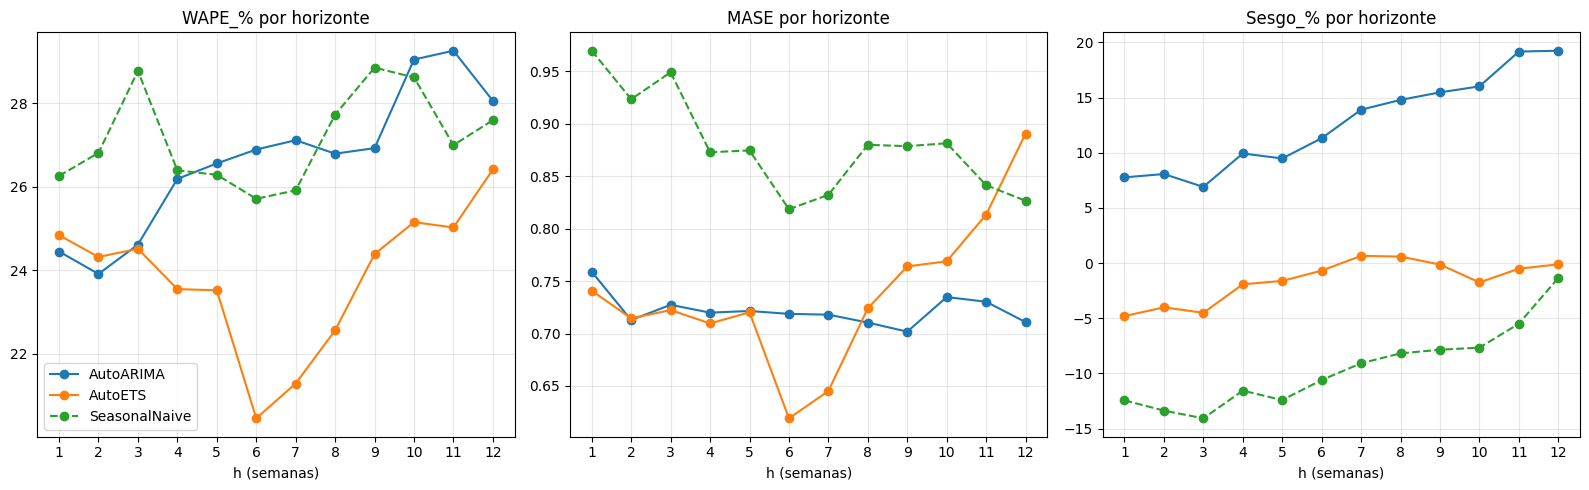


--- GENERANDO GRÁFICO DE COMPETENCIA (ÚLTIMO PLIEGUE) ---


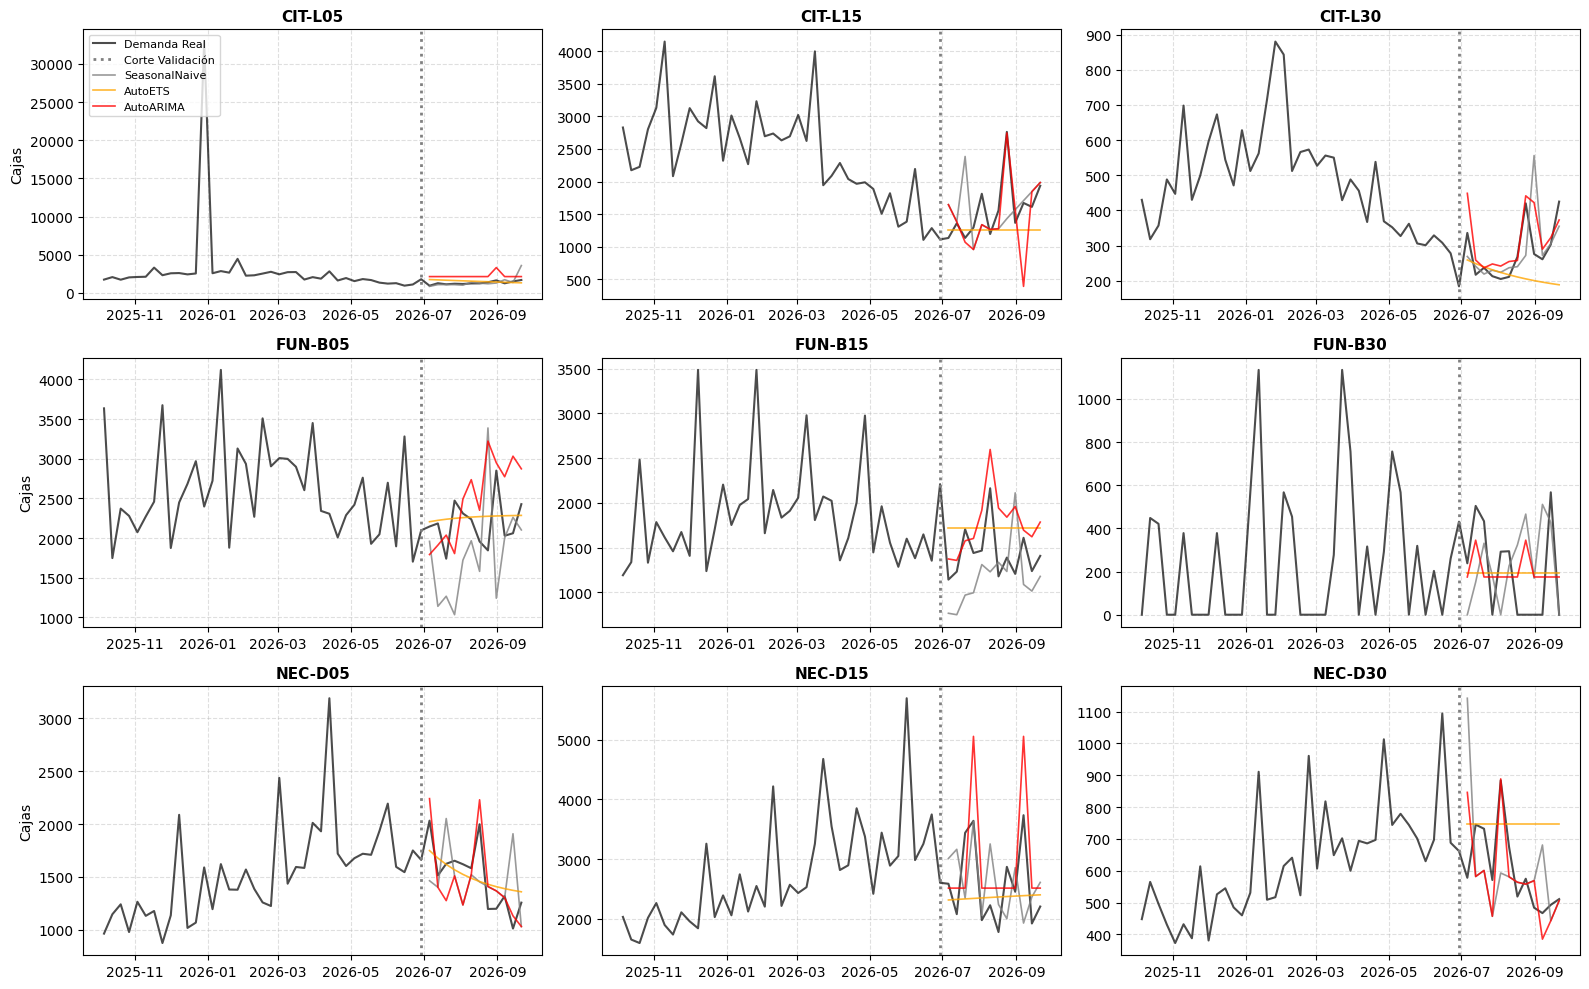

>> OBSERVACIÓN VISUAL:
La línea punteada gris marca el final del entrenamiento del último pliegue.
--------------------------------------------------

--- EJECUTANDO SELECCIÓN AUTOMÁTICA (REGLAS DEL CURSO) ---
🏆 GANADOR SELECCIONADO AUTOMÁTICAMENTE: AutoETS



In [42]:
# =====================================================================
# PARTE B.4 - VALIDACIÓN, GRÁFICAS Y SELECCIÓN AUTOMÁTICA
# =====================================================================

print("\n=====================================================================")
print("PARTE B.4: VALIDACIÓN, GRÁFICAS Y SELECCIÓN AUTOMÁTICA")
print("=====================================================================")

print("Ejecutando Validación Cruzada (Rolling Origin con 8 ventanas)... Por favor, espera.")
# Usamos el motor 'sf' y los datos 'df_sf' que preparamos en B.3
cv_df = sf.cross_validation(df=df_sf, h=horizonte, n_windows=ventanas, step_size=paso)

# Extraemos los nombres reales que StatsForecast le dio a los modelos dinámicamente.
cv_df['h'] = cv_df.groupby(['unique_id', 'cutoff']).cumcount() + 1
columnas_excluir = ['unique_id', 'ds', 'cutoff', 'y', 'promocion', 'h']
nombres_modelos_reales = [col for col in cv_df.columns if col not in columnas_excluir]

# Derretir el DataFrame para facilitar los cálculos
cv_melt = cv_df.melt(
    id_vars=['unique_id', 'ds', 'cutoff', 'y', 'h'],
    value_vars=nombres_modelos_reales,
    var_name='Modelo', value_name='Prediccion'
)

# =====================================================================
# CORRECCIÓN RÚBRICA (HALLAZGO 2): CÁLCULO DE MASE IN-SAMPLE
# =====================================================================
# 1. Aislamos la historia estricta (antes del primer corte de CV)
primer_corte = cv_df['cutoff'].min()
train_inicial = df_sf[df_sf['ds'] <= primer_corte]

# 2. Calculamos el MAE in-sample del Naive Estacional (m=52) para cada SKU
denom_mase_dict = {}
m = temporada # 52 semanas
for sku, df_sub in train_inicial.groupby('unique_id'):
    y_vals = df_sub['y'].values
    if len(y_vals) > m:
        mae_in_sample = np.mean(np.abs(y_vals[m:] - y_vals[:-m]))
    else:
        mae_in_sample = 1.0 # Resguardo
    denom_mase_dict[sku] = mae_in_sample if mae_in_sample > 0 else 1.0

# 3. Mapeamos el denominador al dataframe de validación cruzada
cv_melt['Denom_MASE'] = cv_melt['unique_id'].map(denom_mase_dict)

# =====================================================================
# CÁLCULO DE MÉTRICAS GLOBALES (PUNTO 4 RÚBRICA: POR HORIZONTE h)
# =====================================================================
def calcular_metricas_globales(df):
    suma_y = df['y'].sum()
    suma_err_abs = (df['y'] - df['Prediccion']).abs().sum()
    suma_err_sesgo = (df['Prediccion'] - df['y']).sum()

    wape = (suma_err_abs / suma_y) * 100 if suma_y != 0 else np.nan
    sesgo_pct = (suma_err_sesgo / suma_y) * 100 if suma_y != 0 else np.nan
    # MASE es el error absoluto de la predicción sobre el denominador in-sample
    mase_promedio = ( (df['y'] - df['Prediccion']).abs() / df['Denom_MASE'] ).mean()

    return pd.Series({'WAPE_%': wape, 'Sesgo_%': sesgo_pct, 'MASE': mase_promedio})

metricas_h = cv_melt.groupby(['Modelo', 'h']).apply(calcular_metricas_globales).reset_index()

print("\n--- TABLA: MÉTRICAS POR HORIZONTE (WAPE, MASE Y SESGO) ---")
tabla_b4_pivot = metricas_h.pivot(index='h', columns='Modelo', values=['WAPE_%', 'MASE', 'Sesgo_%']).round(2)
display(tabla_b4_pivot)


# --- GRÁFICO DE DEGRADACIÓN DEL PRONÓSTICO ---
b_fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5), sharex=True)
metricas_grafico = ['WAPE_%', 'MASE', 'Sesgo_%']
b_ejes = [ax1, ax2, ax3]

for metrica, b_ax in zip(metricas_grafico, b_ejes):
    for modelo in metricas_h['Modelo'].unique():
        b_datos = metricas_h[metricas_h['Modelo'] == modelo]
        if modelo == 'SeasonalNaive':
            b_ax.plot(b_datos['h'], b_datos[metrica], label=modelo, marker='o', linestyle='--')
        else:
            b_ax.plot(b_datos['h'], b_datos[metrica], label=modelo, marker='o')

    b_ax.set_title(f'{metrica} por horizonte', fontsize=12)
    b_ax.set_xlabel('h (semanas)', fontsize=10)
    b_ax.grid(alpha=0.3)
    b_ax.set_xticks(range(1, horizonte + 1))
    if metrica == 'WAPE_%':
        b_ax.legend()

plt.tight_layout()
plt.show()

# --- GRÁFICO DE COMPETENCIA (ÚLTIMO PLIEGUE) ---
print("\n--- GENERANDO GRÁFICO DE COMPETENCIA (ÚLTIMO PLIEGUE) ---")
ultimo_corte = cv_df['cutoff'].max()
cv_ultimo = cv_df[cv_df['cutoff'] == ultimo_corte].copy()

skus_unicos = sorted(df_sf['unique_id'].unique())
b_fig, axes = plt.subplots(3, 3, figsize=(16, 10), sharex=False)
axes = axes.flatten()
colores_modelos = {'SeasonalNaive': 'grey', 'AutoETS': 'orange', 'AutoARIMA': 'red'}

for b_i, b_sku in enumerate(skus_unicos):
    if b_i >= 9: break
    b_ax = axes[b_i]
    df_real = df_sf[df_sf['unique_id'] == b_sku]
    df_pred = cv_ultimo[cv_ultimo['unique_id'] == b_sku]
    df_real_recorte = df_real[df_real['ds'] >= df_real['ds'].max() - pd.Timedelta(weeks=50)]

    b_ax.plot(df_real_recorte['ds'], df_real_recorte['y'], label='Demanda Real', color='black', linewidth=1.5, alpha=0.7)
    b_ax.axvline(x=ultimo_corte, color='gray', linestyle=':', linewidth=2, label='Corte Validación')

    for modelo in ['SeasonalNaive', 'AutoETS', 'AutoARIMA']:
        if modelo in df_pred.columns:
            b_ax.plot(df_pred['ds'], df_pred[modelo], label=modelo, color=colores_modelos.get(modelo, 'blue'), linewidth=1.2, alpha=0.8)

    b_ax.set_title(b_sku, fontsize=11, fontweight='bold')
    b_ax.grid(True, linestyle='--', alpha=0.4)
    if b_i % 3 == 0: b_ax.set_ylabel('Cajas', fontsize=10)
    if b_i == 0: b_ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

print(">> OBSERVACIÓN VISUAL:")
print("La línea punteada gris marca el final del entrenamiento del último pliegue.")
print("-" * 50)


# --- ALGORITMO DE SELECCIÓN AUTOMÁTICA ---
print("\n--- EJECUTANDO SELECCIÓN AUTOMÁTICA (REGLAS DEL CURSO) ---")
b_resumen = metricas_h.groupby('Modelo').agg(
    WAPE_mean=('WAPE_%', 'mean'), WAPE_std=('WAPE_%', 'std'),
    MASE_mean=('MASE', 'mean'), Sesgo_mean=('Sesgo_%', 'mean')
).reset_index()

candidatos = b_resumen[(b_resumen['Modelo'] != 'SeasonalNaive') & (b_resumen['MASE_mean'] < 1.0)]
if candidatos.empty:
    print("¡ALERTA! Ningún modelo superó al benchmark. Se fuerza la elección del mejor WAPE general.")
    candidatos = b_resumen[b_resumen['Modelo'] != 'SeasonalNaive']

mejor_wape = candidatos['WAPE_mean'].min()
std_mejor = candidatos.loc[candidatos['WAPE_mean'].idxmin()]['WAPE_std']
empates = candidatos[candidatos['WAPE_mean'] <= (mejor_wape + std_mejor)].copy()

def asignar_simplicidad(nombre):
    if 'ETS' in nombre: return 1
    elif 'ARIMA' in nombre: return 2
    else: return 3

empates['Simplicidad'] = empates['Modelo'].apply(asignar_simplicidad)
empates = empates.sort_values(by=['Simplicidad', 'Sesgo_mean'], ascending=[True, False])
nombre_ganador = empates.iloc[0]['Modelo']

print(f"🏆 GANADOR SELECCIONADO AUTOMÁTICAMENTE: {nombre_ganador}\n")



In [49]:
# =====================================================================
# PARTE B.5 - RECONCILIACIÓN Y SELECCIÓN JERÁRQUICA
# =====================================================================
import pandas as pd
import numpy as np
from IPython.display import display
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive
from hierarchicalforecast.methods import BottomUp, TopDown, MiddleOut
from hierarchicalforecast.core import HierarchicalReconciliation
from hierarchicalforecast.utils import aggregate

print("\n=====================================================================")
print("PARTE B.5: RECONCILIACIÓN Y SELECCIÓN JERÁRQUICA")
print("=====================================================================")

# 1. CONSTRUCCIÓN DE LA ESTRUCTURA JERÁRQUICA
df_h = df_sf.copy()
df_h = df_h.rename(columns={'unique_id': 'sku'})
df_h['planta'] = 'Planta_Maipo'
df_h['familia'] = df_h['sku'].str.split('-').str[0]
df_h = df_h[['planta', 'familia', 'sku', 'ds', 'y']]

b_especificacion = [['planta'], ['planta', 'familia'], ['planta', 'familia', 'sku']]
Y_df, S_df, tags = aggregate(df=df_h, spec=b_especificacion)

print(f"--- 1. GENERANDO PRONÓSTICOS BASE JERÁRQUICOS ---")
# Se utiliza el modelo estacional para preservar los picos de demanda del negocio
instancia_base = SeasonalNaive(season_length=temporada)
fcst_h = StatsForecast(models=[instancia_base], freq='W-MON', n_jobs=-1)

# Validación Cruzada para evaluar el error jerárquico
cv_jerarquico = fcst_h.cross_validation(df=Y_df, h=horizonte, n_windows=ventanas, step_size=paso)

print("Reconciliando métodos (Bottom-Up, Top-Down, Middle-Out)...")
metodos_reconciliacion = [
    BottomUp(),
    TopDown(method='forecast_proportions'),
    MiddleOut(middle_level='planta/familia', top_down_method='forecast_proportions')
]
hrec = HierarchicalReconciliation(reconcilers=metodos_reconciliacion)
cv_jerarquico_input = cv_jerarquico.drop(columns=['cutoff'])
Y_rec_cv = hrec.reconcile(Y_hat_df=cv_jerarquico_input, Y_df=Y_df, S_df=S_df, tags=tags)
Y_rec_cv['cutoff'] = cv_jerarquico['cutoff'].values

estrategias = [col for col in Y_rec_cv.columns if col not in ['unique_id', 'ds', 'cutoff', 'y', 'SeasonalNaive']]
nombres_limpios = {c: ('Bottom-Up' if 'BottomUp' in c else 'Top-Down' if 'TopDown' in c else 'Middle-Out' if 'MiddleOut' in c else c) for c in estrategias}
Y_rec_cv = Y_rec_cv.rename(columns=nombres_limpios)

# 2. EVALUACIÓN Y TABLA DE WAPE POR NIVEL JERÁRQUICO
res_jerarquia = []
for nivel, ids in tags.items():
    df_nivel = Y_rec_cv[Y_rec_cv['unique_id'].isin(ids)]
    suma_y_real = df_nivel['y'].sum()

    for estrategia in nombres_limpios.values():
        if suma_y_real > 0:
            suma_error_abs = (df_nivel['y'] - df_nivel[estrategia]).abs().sum()
            wape = (suma_error_abs / suma_y_real) * 100
        else:
            wape = np.nan
        res_jerarquia.append({'Nivel Jerárquico': nivel, 'Estrategia': estrategia, 'WAPE_%': round(wape, 2)})

tabla_jerarquia = pd.DataFrame(res_jerarquia).pivot(index='Nivel Jerárquico', columns='Estrategia', values='WAPE_%')
tabla_jerarquia = tabla_jerarquia.reindex(['planta', 'planta/familia', 'planta/familia/sku'])

print("\n--- TABLA: COMPARATIVA DE ERROR (WAPE %) POR NIVEL JERÁRQUICO ---")
display(tabla_jerarquia)

errores_sku = tabla_jerarquia.loc['planta/familia/sku']
enfoque_ganador = errores_sku.idxmin()
wape_ganador = errores_sku.min()
print(f"\n🏆 ENFOQUE JERÁRQUICO SELECCIONADO: {enfoque_ganador} (Mejor WAPE a nivel SKU: {wape_ganador:.2f}%)")

# 3. GENERACIÓN DEL PRONÓSTICO FUTURO (13 SEMANAS) CON INTERVALOS DE CONFIANZA
print("\nGenerando pronóstico futuro a 13 semanas con intervalos empíricos (Bootstrap)...")
Y_hat_base_final = fcst_h.forecast(df=Y_df, h=horizonte, fitted=True, level=[80, 95])
Y_fitted_final = fcst_h.forecast_fitted_values()

Y_rec_final = hrec.reconcile(
    Y_hat_df=Y_hat_base_final,
    Y_df=Y_fitted_final,
    S_df=S_df,
    tags=tags,
    level=[80, 95],
    intervals_method='bootstrap'
)

columnas_ganador = [col for col in Y_rec_final.columns if enfoque_ganador.replace('-', '') in col.replace('-', '')]
Y_rec_final_limpio = Y_rec_final[['unique_id', 'ds'] + columnas_ganador].copy()

mapeo_columnas_finales = {
    col: 'Pronostico_Final_Cajas' if col.endswith(enfoque_ganador) or col.endswith(enfoque_ganador.replace('-', ''))
    else col.replace(enfoque_ganador, 'Int').replace(enfoque_ganador.replace('-', ''), 'Int')
    for col in columnas_ganador
}
pronostico_oficial = Y_rec_final_limpio.rename(columns=mapeo_columnas_finales)

# Truncado de negativos a 0 y redondeo a cajas enteras
for col in pronostico_oficial.columns:
    if col not in ['unique_id', 'ds']:
        pronostico_oficial[col] = pronostico_oficial[col].round().clip(lower=0)

print("✅ PARTE B.5 COMPLETADA EXITOSAMENTE.")


PARTE B.5: RECONCILIACIÓN Y SELECCIÓN JERÁRQUICA
--- 1. GENERANDO PRONÓSTICOS BASE JERÁRQUICOS ---
Reconciliando métodos (Bottom-Up, Top-Down, Middle-Out)...

--- TABLA: COMPARATIVA DE ERROR (WAPE %) POR NIVEL JERÁRQUICO ---


Estrategia,Bottom-Up,Middle-Out,Top-Down
Nivel Jerárquico,,,
planta,10.46,10.46,10.46
planta/familia,19.91,19.91,19.91
planta/familia/sku,27.15,27.15,27.15



🏆 ENFOQUE JERÁRQUICO SELECCIONADO: Bottom-Up (Mejor WAPE a nivel SKU: 27.15%)

Generando pronóstico futuro a 13 semanas con intervalos empíricos (Bootstrap)...
✅ PARTE B.5 COMPLETADA EXITOSAMENTE.



PARTE B.6: PRONÓSTICO FINAL, FAN CHARTS Y TABLAS DE AUDITORÍA
--- AUDITORÍA: VERIFICACIÓN DE COHERENCIA MATEMÁTICA ---
Suma Total proyectada en la base (SKUs):      160,778 cajas
Suma Total proyectada en el medio (Familias): 160,778 cajas
Pronóstico Total agregado arriba (Planta):    160,778 cajas
>> Veredicto: ¡COHERENCIA PERFECTA! (One Number garantizado)

--- GENERANDO FAN CHARTS (PROYECCIÓN 13 SEMANAS CON INTERVALOS) ---


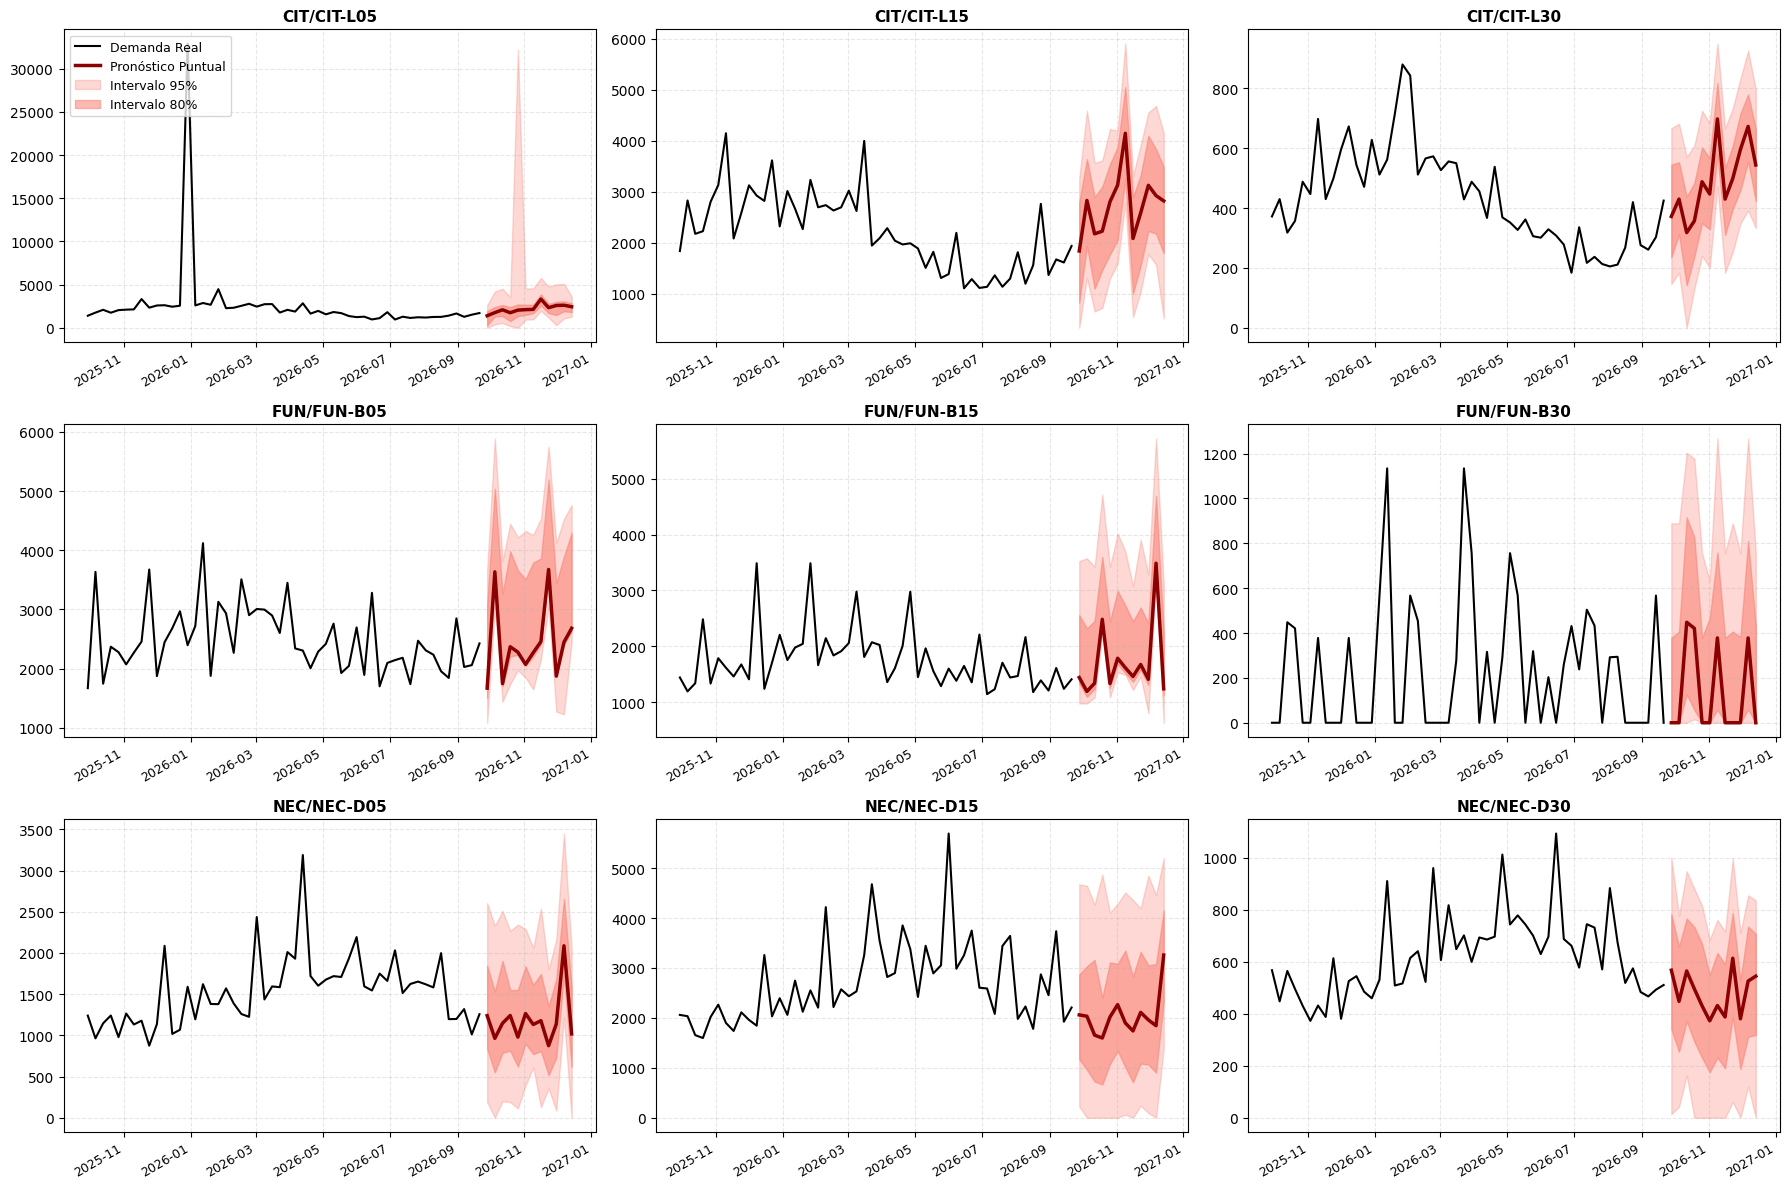


--- TABLA 1: PRONÓSTICO TOTAL ACUMULADO (DEMANDA PRÓXIMO TRIMESTRE POR SKU) ---


,SKU,Total_Cajas_13_Semanas
0,CIT/CIT-L15,32683.0
1,FUN/FUN-B05,29185.0
2,CIT/CIT-L05,26500.0
3,NEC/NEC-D15,24442.0
4,FUN/FUN-B15,20461.0
5,NEC/NEC-D05,14263.0
6,CIT/CIT-L30,5852.0
7,NEC/NEC-D30,5767.0
8,FUN/FUN-B30,1625.0



--- TABLA 2: DESGLOSE SEMANAL DEL PRONÓSTICO (EJEMPLO: SKU MÁS CRÍTICO) ---


,Limite_Inf_95%,Limite_Inf_80%,Pronostico_Puntual,Limite_Sup_80%,Limite_Sup_95%
Fecha_Lunes,,,,,
2026-09-28,0.0,281.0,1392.0,1927.0,2601.0
2026-10-05,396.0,1320.0,1753.0,2402.0,4198.0
2026-10-12,551.0,1353.0,2080.0,2625.0,4524.0
2026-10-19,192.0,768.0,1740.0,2389.0,3547.0
2026-10-26,0.0,1346.0,2042.0,2691.0,32195.0
2026-11-02,942.0,1481.0,2097.0,2660.0,4541.0
2026-11-09,967.0,1688.0,2126.0,2659.0,4570.0
2026-11-16,1960.0,2589.0,3321.0,3856.0,5766.0
2026-11-23,1176.0,1703.0,2326.0,2770.0,4771.0



--- TABLA 3: COHERENCIA JERÁRQUICA VERIFICADA ---


,Nivel,Volumen_Total_Cajas,Diferencia_vs_Planta
0,Base (Suma de 9 SKUs),160778.0,0.0
1,Medio (Suma de 3 Familias),160778.0,0.0
2,Agregado (Planta Maipo),160778.0,0.0


In [51]:
# =====================================================================
# PARTE B.6 - PRONÓSTICO FINAL, FAN CHARTS Y TABLAS DE AUDITORÍA S&OP
# =====================================================================
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
from IPython.display import display

print("\n=====================================================================")
print("PARTE B.6: PRONÓSTICO FINAL, FAN CHARTS Y TABLAS DE AUDITORÍA")
print("=====================================================================")

col_puntual = 'Pronostico_Final_Cajas'
cols_95 = [c for c in pronostico_oficial.columns if '95' in c]
cols_80 = [c for c in pronostico_oficial.columns if '80' in c]

lim_inf_95 = [c for c in cols_95 if 'lo' in c.lower() or 'inf' in c.lower()][0]
lim_sup_95 = [c for c in cols_95 if 'hi' in c.lower() or 'sup' in c.lower()][0]
lim_inf_80 = [c for c in cols_80 if 'lo' in c.lower() or 'inf' in c.lower()][0]
lim_sup_80 = [c for c in cols_80 if 'hi' in c.lower() or 'sup' in c.lower()][0]

# --- 1. AUDITORÍA DE COHERENCIA MATEMÁTICA (ONE NUMBER) ---
suma_skus = pronostico_oficial[pronostico_oficial['unique_id'].isin(tags['planta/familia/sku'])][col_puntual].sum()
suma_familias = pronostico_oficial[pronostico_oficial['unique_id'].isin(tags['planta/familia'])][col_puntual].sum()
suma_planta = pronostico_oficial[pronostico_oficial['unique_id'] == 'Planta_Maipo'][col_puntual].sum()

print("--- AUDITORÍA: VERIFICACIÓN DE COHERENCIA MATEMÁTICA ---")
print(f"Suma Total proyectada en la base (SKUs):      {suma_skus:,.0f} cajas")
print(f"Suma Total proyectada en el medio (Familias): {suma_familias:,.0f} cajas")
print(f"Pronóstico Total agregado arriba (Planta):    {suma_planta:,.0f} cajas")

if round(suma_skus) == round(suma_planta):
    print(">> Veredicto: ¡COHERENCIA PERFECTA! (One Number garantizado)")
else:
    print(f">> Veredicto: Diferencia mínima por redondeo detectada: {suma_skus - suma_planta:.0f} cajas.")

# --- 2. GENERACIÓN DE FAN CHARTS (SUBGRÁFICOS 3x3) ---
print("\n--- GENERANDO FAN CHARTS (PROYECCIÓN 13 SEMANAS CON INTERVALOS) ---")
skus_base = tags['planta/familia/sku']
fig, axes = plt.subplots(3, 3, figsize=(18, 12), sharex=False)
axes = axes.flatten()

for b_i, b_sku in enumerate(skus_base):
    if b_i >= 9: break
    b_ax = axes[b_i]

    # Historia reciente (últimas 52 semanas) y pronóstico futuro
    df_real = Y_df[Y_df['unique_id'] == b_sku].tail(52)
    df_pred = pronostico_oficial[pronostico_oficial['unique_id'] == b_sku]

    # Línea de Demanda Real y Pronóstico Puntual
    b_ax.plot(df_real['ds'], df_real['y'], label='Demanda Real', color='black', linewidth=1.5)
    b_ax.plot(df_pred['ds'], df_pred[col_puntual], label='Pronóstico Puntual', color='darkred', linewidth=2.5)

    # Abanicos de incertidumbre (Fan Chart)
    b_ax.fill_between(df_pred['ds'], df_pred[lim_inf_95], df_pred[lim_sup_95], color='salmon', alpha=0.3, label='Intervalo 95%')
    b_ax.fill_between(df_pred['ds'], df_pred[lim_inf_80], df_pred[lim_sup_80], color='salmon', alpha=0.55, label='Intervalo 80%')

    # Título y cuadrícula
    titulo_limpio = b_sku.replace('Planta_Maipo/', '')
    b_ax.set_title(titulo_limpio, fontweight='bold', fontsize=11)
    b_ax.grid(alpha=0.3, linestyle='--')

    # Formato de fechas en el eje X para evitar empalmes
    b_ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    b_ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.setp(b_ax.xaxis.get_majorticklabels(), rotation=30, ha='right', fontsize=9)

    if b_i == 0:
        b_ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

# --- 3. TABLA 1: VOLUMEN ACUMULADO PRÓXIMO TRIMESTRE (13 SEMANAS) ---
print("\n--- TABLA 1: PRONÓSTICO TOTAL ACUMULADO (DEMANDA PRÓXIMO TRIMESTRE POR SKU) ---")
tabla_volumen = pronostico_oficial[pronostico_oficial['unique_id'].isin(tags['planta/familia/sku'])].copy()
volumen_total = tabla_volumen.groupby('unique_id')[col_puntual].sum().reset_index()
volumen_total = volumen_total.rename(columns={'unique_id': 'SKU', col_puntual: 'Total_Cajas_13_Semanas'})
volumen_total['SKU'] = volumen_total['SKU'].str.replace('Planta_Maipo/', '')
volumen_total = volumen_total.sort_values(by='Total_Cajas_13_Semanas', ascending=False).reset_index(drop=True)
display(volumen_total)

# --- 4. TABLA 2: DESGLOSE SEMANAL DEL SKU CRÍTICO CON INTERVALOS ---
print("\n--- TABLA 2: DESGLOSE SEMANAL DEL PRONÓSTICO (EJEMPLO: SKU MÁS CRÍTICO) ---")
sku_critico_tag = tags['planta/familia/sku'][0]
ejemplo_sku = pronostico_oficial[pronostico_oficial['unique_id'] == sku_critico_tag].copy()

cols_mostrar = ['ds', lim_inf_95, lim_inf_80, col_puntual, lim_sup_80, lim_sup_95]
ejemplo_sku = ejemplo_sku[cols_mostrar].rename(columns={
    'ds': 'Fecha_Lunes',
    lim_inf_95: 'Limite_Inf_95%',
    lim_inf_80: 'Limite_Inf_80%',
    col_puntual: 'Pronostico_Puntual',
    lim_sup_80: 'Limite_Sup_80%',
    lim_sup_95: 'Limite_Sup_95%'
})
display(ejemplo_sku.set_index('Fecha_Lunes'))

# --- 5. TABLA 3: COHERENCIA JERÁRQUICA S&OP (ONE NUMBER) ---
print("\n--- TABLA 3: COHERENCIA JERÁRQUICA VERIFICADA ---")
df_coherencia = pd.DataFrame({
    'Nivel': ['Base (Suma de 9 SKUs)', 'Medio (Suma de 3 Familias)', 'Agregado (Planta Maipo)'],
    'Volumen_Total_Cajas': [suma_skus, suma_familias, suma_planta]
})
df_coherencia['Diferencia_vs_Planta'] = df_coherencia['Volumen_Total_Cajas'] - suma_planta
display(df_coherencia)

# Parte C: El puente hacia la Entrega 2


In [52]:
# ============================================================
# PARTE C — PARÁMETROS DE TRASPASO A LA ENTREGA 2
# Utiliza los datos y resultados ya calculados en A y B.
# ============================================================


# ------------------------------------------------------------
# C.1. MERMA EFECTIVA POR LÍNEA
# Semanas 1 a 10 originales, sin exclusiones.
# Supuesto: las botellas defectuosas no son vendibles.
# ------------------------------------------------------------

base_merma_c = atributos[
    atributos["semana_registro"].between(1, 10)
].copy()

merma_traspaso = (
    base_merma_c.groupby("linea", as_index=False)
    .agg(
        inspeccionadas=("n_inspeccionadas", "sum"),
        defectuosas=("n_defectuosas", "sum")
    )
)

# Proporción ponderada: no promediar porcentajes individuales.
merma_traspaso["rho"] = (
    merma_traspaso["defectuosas"]
    / merma_traspaso["inspeccionadas"]
)

# Producción requerida para obtener x cajas vendibles:
# x / (1 - rho).
merma_traspaso["factor_produccion"] = (
    1 / (1 - merma_traspaso["rho"])
)


# ------------------------------------------------------------
# C.2. SOBRELLENADO MEDIO POR FORMATO
# Semanas 1 a 10 originales, sin exclusiones.
# ------------------------------------------------------------

base_llenado_c = llenado[
    llenado["semana_registro"].between(1, 10)
].copy()

botellas_formato_c = maestro_atributos[
    ["formato_L", "botellas_por_caja"]
].drop_duplicates()

if botellas_formato_c["formato_L"].duplicated().any():
    raise ValueError(
        "Un formato tiene diferentes cantidades de botellas "
        "por caja. Debe revisarse la conversión por SKU."
    )

sobrellenado_traspaso = (
    base_llenado_c.groupby("formato_L", as_index=False)
    .agg(media_mL=("volumen_mL", "mean"))
)

sobrellenado_traspaso = sobrellenado_traspaso.merge(
    especificaciones[["formato_L", "nominal_mL"]],
    on="formato_L",
    how="left",
    validate="one_to_one"
).merge(
    botellas_formato_c,
    on="formato_L",
    how="left",
    validate="one_to_one"
)

if sobrellenado_traspaso[
    ["nominal_mL", "botellas_por_caja"]
].isna().any().any():
    raise ValueError(
        "Falta el volumen nominal o la cantidad de botellas por caja."
    )

# Diferencia entre el volumen medio y el nominal.
# Una media inferior al nominal no representa sobrellenado.
sobrellenado_traspaso["sobrellenado_mL_botella"] = (
    sobrellenado_traspaso["media_mL"]
    - sobrellenado_traspaso["nominal_mL"]
).clip(lower=0)

# Conversión a litros adicionales por caja producida.
sobrellenado_traspaso["adicional_L_caja"] = (
    sobrellenado_traspaso["sobrellenado_mL_botella"]
    * sobrellenado_traspaso["botellas_por_caja"]
    / 1000
)

In [53]:
# ------------------------------------------------------------
# C.3 Y C.4. PRONÓSTICO Y DESVIACIÓN DEL ERROR
# Se toman del resultado final de B, por SKU y horizonte.
# No se vuelven a ajustar los modelos.
# ------------------------------------------------------------

pronostico_traspaso = pronostico_final[
    pronostico_final["unique_id"].isin(
        tags["planta/familia/sku"]
    )
][[
    "unique_id",
    "ds",
    "h",
    "Pronostico_Puntual",
    "Sigma_Error"
]].copy()

# Recuperar el código SKU desde su identificador jerárquico.
pronostico_traspaso["sku"] = (
    pronostico_traspaso["unique_id"].str.split("/").str[-1]
)

pronostico_traspaso = pronostico_traspaso.rename(
    columns={
        "ds": "fecha_lunes",
        "h": "horizonte",
        "Pronostico_Puntual": "pronostico_cajas",
        "Sigma_Error": "sigma_error_cajas"
    }
)

pronostico_traspaso = pronostico_traspaso[[
    "sku",
    "horizonte",
    "fecha_lunes",
    "pronostico_cajas",
    "sigma_error_cajas"
]].sort_values(
    ["sku", "horizonte"]
).reset_index(drop=True)

if pronostico_traspaso.duplicated(
    ["sku", "horizonte"]
).any():
    raise ValueError(
        "Hay pronósticos duplicados para un mismo SKU y horizonte."
    )

if pronostico_traspaso[[
    "pronostico_cajas", "sigma_error_cajas"
]].isna().any().any():
    raise ValueError(
        "Falta algún pronóstico o desviación del error en B."
    )

for sku_c, grupo_c in pronostico_traspaso.groupby("sku"):
    if sorted(grupo_c["horizonte"].tolist()) != list(range(1, 14)):
        raise ValueError(
            f"{sku_c}: deben existir los horizontes 1 a 13."
        )

In [54]:
# ------------------------------------------------------------
# C.5. PRESENTACIÓN COMPACTA DE LAS TABLAS
# El redondeo es únicamente visual.
# Los datos numéricos se conservan para la Entrega 2.
# ------------------------------------------------------------

def numero_c(valor, decimales=4):
    if decimales == 0:
        return f"{valor:.0f}"
    return f"{valor:.{decimales}f}".rstrip("0").rstrip(".")


estilo_c = """
<style>
.tabla-parte-c {
    overflow-x: auto;
    color: inherit !important;
    margin-bottom: 14px;
}

.tabla-parte-c table {
    border-collapse: collapse;
    width: auto !important;
    font-size: 12px;
    line-height: 1.2;
}

.tabla-parte-c table,
.tabla-parte-c thead,
.tabla-parte-c tbody,
.tabla-parte-c tr,
.tabla-parte-c th,
.tabla-parte-c td {
    background: transparent !important;
    color: inherit !important;
}

.tabla-parte-c th,
.tabla-parte-c td {
    border: 1px solid currentColor !important;
    padding: 4px 7px !important;
    text-align: center !important;
}

.tabla-parte-c th {
    max-width: 145px;
}

.tabla-parte-c h4 {
    margin: 8px 0;
}
</style>
"""


def mostrar_tabla_c(titulo, tabla):
    display(HTML(
        estilo_c
        + '<div class="tabla-parte-c">'
        + f"<h4>{titulo}</h4>"
        + tabla.to_html(index=False, border=0, escape=True)
        + "</div>"
    ))


# ------------------------------------------------------------
# TABLA C.1 — MERMA OBSERVADA POR LÍNEA
# Sin mostrar el factor de producción.
# ------------------------------------------------------------

tabla_merma_c = pd.DataFrame({
    "Línea": merma_traspaso["linea"],
    "Inspeccionadas": merma_traspaso["inspeccionadas"],
    "Defectuosas": merma_traspaso["defectuosas"],
    "Merma observada (%)": (
        100 * merma_traspaso["rho"]
    ).map(lambda valor: numero_c(valor, 3).replace(".", ",")),
    "ρ (proporción)": merma_traspaso["rho"].map(
        lambda valor: numero_c(valor, 6).replace(".", ",")
    )
})

mostrar_tabla_c(
    "C.1 — Merma observada por línea",
    tabla_merma_c
)

for _, fila_c in merma_traspaso.iterrows():

    porcentaje_c = numero_c(
        100 * fila_c["rho"], 3
    ).replace(".", ",")

    print(
        f"{fila_c['linea']}: se registraron "
        f"{int(fila_c['defectuosas'])} botellas defectuosas "
        f"de {int(fila_c['inspeccionadas'])} inspeccionadas, "
        f"equivalentes a una merma observada del {porcentaje_c}%."
    )



# ------------------------------------------------------------
# TABLA C.2 — SOBRELLENADO MEDIO POR FORMATO
# Jarabe corresponde al jugo o bebida terminada.
# Se utiliza coma decimal para facilitar la lectura.
# ------------------------------------------------------------

tabla_sobrellenado_c = pd.DataFrame({
    "Formato (L)": sobrellenado_traspaso["formato_L"].map(
        lambda valor: numero_c(valor).replace(".", ",")
    ),
    "Sobrellenado medio (mL/botella)":
        sobrellenado_traspaso["sobrellenado_mL_botella"].map(
            lambda valor: numero_c(valor, 4).replace(".", ",")
        ),
    "Botellas/caja":
        sobrellenado_traspaso["botellas_por_caja"].astype(int),
    "Jarabe adicional (L/caja)":
        sobrellenado_traspaso["adicional_L_caja"].map(
            lambda valor: numero_c(valor, 6).replace(".", ",")
        )
})

mostrar_tabla_c(
    "C.2 — Sobrellenado medio y consumo adicional por caja",
    tabla_sobrellenado_c
)

print(
    "\nPara la planificación de producción e inventarios de la "
    "Entrega 2, estos litros adicionales se considerarán en el consumo "
    "adicional de mezcla y materias primas que genera el sobrellenado, "
    "sin aumentar la cantidad de cajas vendibles."
)

# Tabla 3: pronóstico y desviación del error.
# Cada fila corresponde a un SKU y una semana futura.

tabla_pronostico_c = pd.DataFrame({
    "SKU": pronostico_traspaso["sku"],
    "Horizonte": pronostico_traspaso["horizonte"].astype(int),
    "Semana desde": pronostico_traspaso["fecha_lunes"].dt.strftime(
        "%d-%m-%Y"
    ),
    "Pronóstico (cajas)": pronostico_traspaso[
        "pronostico_cajas"
    ].map(lambda valor: numero_c(valor, 0)),
    "Desviación del error (cajas)": pronostico_traspaso[
        "sigma_error_cajas"
    ].map(lambda valor: numero_c(valor, 2))
})

mostrar_tabla_c(
    "C.3–C.4 — Pronóstico y desviación del error por SKU y horizonte",
    tabla_pronostico_c
)

print(
    "Calidad: parámetros estimados con las semanas 1 a 10 "
    "originales, sin exclusiones."
)

print(
    "Merma: se considera que las botellas defectuosas "
    "no son vendibles."
)

print(
    "Sobrellenado: litros adicionales de bebida terminada "
    "por caja, utilizados como consumo adicional de mezcla."
)

print(
    f"Pronóstico: se conservan los resultados de B "
    f"({nombre_ganador} + {enfoque_ganador})."
)

print(
    "La desviación del error está expresada en cajas "
    "por SKU y horizonte; no es todavía el stock de seguridad."
)


Línea,Inspeccionadas,Defectuosas,Merma observada (%),ρ (proporción)
L1,12905,248,"1,922","0,019217"
L2,32974,1027,"3,115","0,031146"


L1: se registraron 248 botellas defectuosas de 12905 inspeccionadas, equivalentes a una merma observada del 1,922%.
L2: se registraron 1027 botellas defectuosas de 32974 inspeccionadas, equivalentes a una merma observada del 3,115%.


Formato (L),Sobrellenado medio (mL/botella),Botellas/caja,Jarabe adicional (L/caja)
"0,5","4,0936",12,"0,049123"
"1,5","4,6011",6,"0,027606"
3,"8,5012",4,"0,034005"



Para la planificación de producción e inventarios de la Entrega 2, estos litros adicionales se considerarán en el consumo adicional de mezcla y materias primas que genera el sobrellenado, sin aumentar la cantidad de cajas vendibles.


SKU,Horizonte,Semana desde,Pronóstico (cajas),Desviación del error (cajas)
CIT-L05,1,28-09-2026,1593,245.25
CIT-L05,2,05-10-2026,1866,341.85
CIT-L05,3,12-10-2026,1826,377.53
CIT-L05,4,19-10-2026,2224,469.97
CIT-L05,5,26-10-2026,2498,463.5
CIT-L05,6,02-11-2026,2212,482.64
CIT-L05,7,09-11-2026,2014,419.57
CIT-L05,8,16-11-2026,2840,402.1
CIT-L05,9,23-11-2026,2445,424.99
CIT-L05,10,30-11-2026,3737,426.41


Calidad: parámetros estimados con las semanas 1 a 10 originales, sin exclusiones.
Merma: se considera que las botellas defectuosas no son vendibles.
Sobrellenado: litros adicionales de bebida terminada por caja, utilizados como consumo adicional de mezcla.
Pronóstico: se conservan los resultados de B (AutoETS + Bottom-Up).
La desviación del error está expresada en cajas por SKU y horizonte; no es todavía el stock de seguridad.
